## Курс математической статистики и разбор кейсов



1. Генеральная совокупность и выборка

- Генеральная совокупность (ГС): Полный набор всех объектов, которые мы хотим исследовать (ее объем N часто бесконечен или слишком велик).
- Выборка: Случайная подгруппа объектов объемом n, извлеченная из ГС для непосредственного изучения.
- Репрезентативность: Свойство выборки точно отражать состав и характеристики всей генеральной совокупности.

функция распределения (обычно обозначается как F(x) — это универсальный паспорт случайной величины. Она полностью описывает её вероятностное поведение

- Функция распределения F(x) -CDF — Cumulative Distribution Function- — это вероятность того, что случайная величина X примет значение, строго меньшее, чем заданное число x

 
# Простая аналогия для понимания

Представьте, что вы анализируете рост людей в городе.
Если вы подставите в функцию распределения значение x = 180 cv, то F(180) покажет долю (или вероятность) людей в городе, у которых рост строго меньше 180 см.
- Если F(180) = 0.85, это значит, что 85% населения ниже 180 см.



Как она выглядит для разных типов данных

- 1. Для непрерывных величин (рост, время, вес):
График F(x) представляет собой плавную растущую линию. Она тесно связана с плотностью распределения f(x) (знаменитым «колоколом» Гаусса): функция распределения — это площадь под этим колоколом от минус бесконечности до точки x.
- 2. Для дискретных величин (кубик, количество детей, число отказов):
График F(x) выглядит как ступенчатая лестница. Разрывы (ступеньки) происходят в тех точках, которые случайная величина может принять, а высота ступеньки равна вероятности этого конкретного значения.

In [11]:
# !pip install numpy scipy matplotlib statsmodels

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from statsmodels.distributions.empirical_distribution import ECDF



## Расчет теоретической CDF (Пример с KPI)

Задача: Среднее время обслуживания клиента на кассе составляет 3 минуты (экспоненциальное распределение). Какова вероятность, что случайный клиент проведет в очереди меньше 5 минут?

In [12]:
# Задаем среднее время = 3 минуты (параметр scale в scipy)
mean_time = 3

# Ищем накопленную вероятность для x = 5 минут
p = stats.expon.cdf(5, scale=mean_time)

print(f"Теоретический расчет:")
print(f"Вероятность обслужить клиента быстрее, чем за 5 минут: {p:.2%}")


Теоретический расчет:
Вероятность обслужить клиента быстрее, чем за 5 минут: 81.11%



## Построение ECDF по реальным данным

Задача: У нас есть данные по зарплатам сотрудников (в тыс. рублей). Нужно построить график распределения, узнать долю людей с доходом ниже 70 тысяч и определить 90-й перцентиль (порог, ниже которого зарабатывают 90% штата).

Анализ выборки:
Доля сотрудников с зарплатой < 70 тыс. руб.: 53.3%
90% сотрудников зарабатывают меньше, чем: 104.0 тыс. руб.



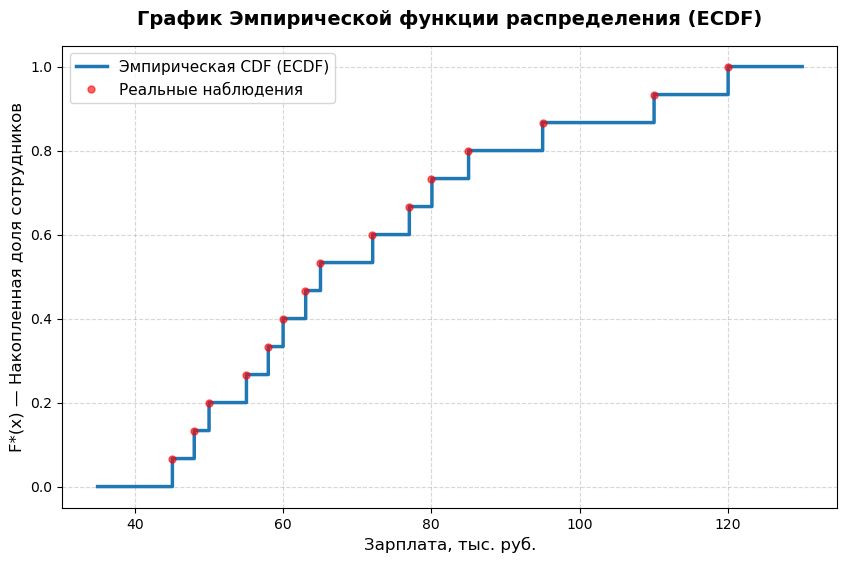

In [13]:
# Набор реальных данных (выборка)
salaries = np.array([45, 55, 60, 80, 120, 48, 65, 72, 95, 50, 58, 85, 110, 63, 77])

# 1. Вычисляем эмпирическую функцию распределения
ecdf = ECDF(salaries)

# 2. Узнаем точную долю сотрудников с ЗП ниже 70 тыс. руб.
share_below_70 = ecdf(70)
print("Анализ выборки:")
print(f"Доля сотрудников с зарплатой < 70 тыс. руб.: {share_below_70:.1%}")

# 3. Находим 90-й перцентиль
percentile_90 = np.percentile(salaries, 90)
print(f"90% сотрудников зарабатывают меньше, чем: {percentile_90:.1f} тыс. руб.\n")

# 4. Визуализация графиков
plt.figure(figsize=(10, 6))

# Генерируем плавную сетку для отрисовки "ступенек"
x_steps = np.linspace(min(salaries) - 10, max(salaries) + 10, 1000)

# Рисуем ступенчатый график ECDF
plt.step(x_steps, ecdf(x_steps), where='post', color='#1f77b4', linewidth=2.5, label='Эмпирическая CDF (ECDF)')

# Добавляем маркеры реальных точек данных на график для наглядности
plt.plot(np.sort(salaries), ecdf(np.sort(salaries)), 'ro', markersize=5, label='Реальные наблюдения', alpha=0.6)

# Оформление графика
plt.title("График Эмпирической функции распределения (ECDF)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Зарплата, тыс. руб.", fontsize=12)
plt.ylabel("F*(x) — Накопленная доля сотрудников", fontsize=12)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=11)

# Отображаем график
plt.show()


## Главные бизнес-кейсы применения CDF и ECDF

В реальном бизнесе и продуктовой аналитике функции распределения ценятся сильнее, чем обычное «среднее арифметическое». Среднее значение часто маскирует проблемы (например, если у 90% пользователей сайт открывается за 1 секунду, а у 10% — за 20 секунд, среднее будет ~3 секунды, что не отражает реальную картину).

CDF и ECDF помогают увидеть полную картину. Рассмотрим **3 классических бизнес-кейса**.

---

### Кейс 1: Мониторинг SLA и оценка стабильности сервиса (IT и Devops)
**Суть:** Команда инфраструктуры гарантирует, что сайт работает быстро. Бизнес-требование (SLA) звучит так: *«Не менее 95% запросов к серверу должны обрабатываться быстрее, чем за 200 миллисекунд»*.

*   **Как помогает ECDF:** Мы строим график ECDF по времени ответа сервера. Находим на оси Y точку `0.95` (95% всех запросов) и смотрим на соответствующее значение по оси X. 
*   Если X ≤ 200 мс — SLA соблюден.
*   Если X > 200 мс — инженеры получают уведомление о деградации сервиса.

### Кейс 2: Анализ рисков и управление запасами (Логистика и Финтех)
**Суть:** Сеть ресторанов быстрого питания рассчитывает время доставки заказов курьерами, чтобы обещать клиентам: *«Доставим за X минут или вернем деньги»*. При этом компания готова платить компенсацию максимум в 5% случаев (риск-аппетит).

*   **Как помогает CDF:** На основе исторических данных о поездках строится функция распределения времени доставки. 
*   Аналитики ищут **95-й перцентиль** (точку, где накопленная вероятность равна `0.95`). 
*   Полученное время (например, 42 минуты) официально объявляется клиентам как верхняя граница доставки. 5% заказов, которые гарантированно опоздают из-за глухих пробок, закладываются в бюджет как операционные расходы на удержание клиентов.

### Кейс 3: Скоринг клиентов и ценообразование (Маркетинг и Продажи)
**Суть:** Онлайн-кинотеатр хочет запустить новую VIP-подписку. Маркетологам нужно определить порог трат, выше которого пользователя можно считать «китом» (премиальным клиентом), чтобы предложить ему этот продукт.

*   **Как помогает ECDF:** Строится ECDF трат всех активных пользователей за год. 
*   По графику определяется точка `0.90` (90% пользователей тратят меньше этой суммы). Остальные 10% топ-клиентов автоматически попадают в сегмент «VIP».
*   Если график ECDF имеет резкий вертикальный взлет в начале и тянется очень длинным плоским «хвостом» вправо — это классический сигнал сильного расслоения аудитории (закон Парето), где основной доход приносят единицы, и компании жизненно необходимо внедрять дорогие тарифные планы.


95% запросов обработаны быстрее, чем за: 262.7 мс
SLA НАРУШЕН! Требуется оптимизация.


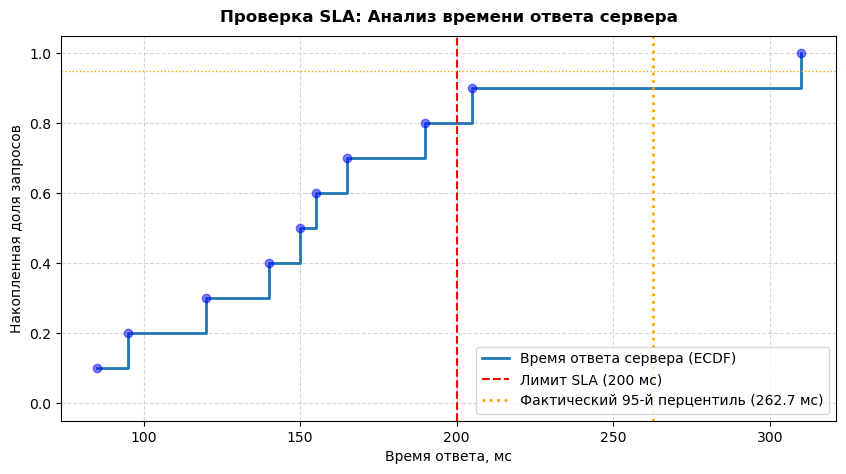

Точный 90-й перцентиль времени доставки: 44.6 мин.
Бизнес-решение: Обещаем клиенту доставку за 45 минут!


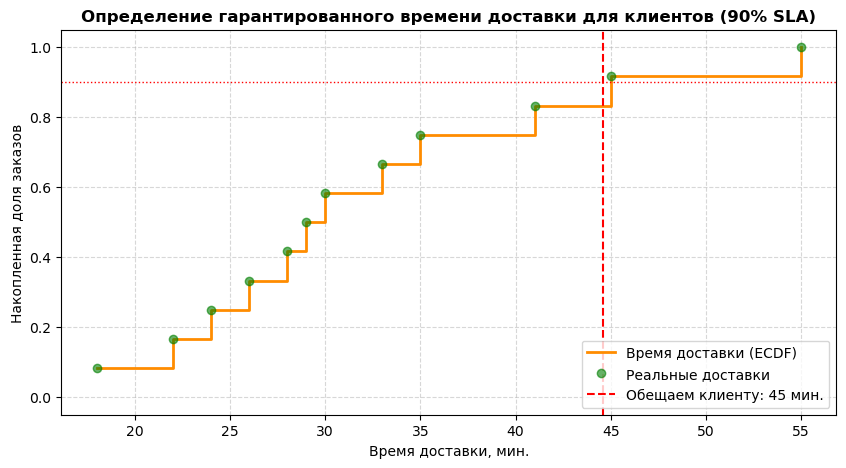

Порог для входа в VIP-клуб: 160,000 руб.


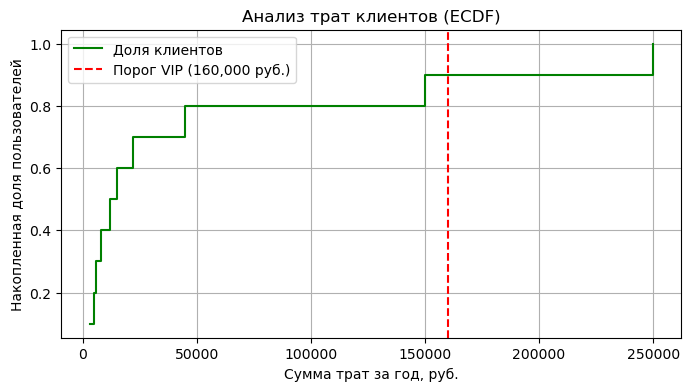

In [15]:
##  Простые примеры кода для бизнес-кейсов

# Ниже представлены максимально простые примеры кода для каждого из трех бизнес-кейсов. Мы используем только базовые функции `numpy` и `matplotlib`, без сложных математических абстракций.

### Код к Кейсу 1: Проверка SLA (Время ответа сервера)
# **Задача:** Проверить, укладываются ли 95% запросов к серверу в лимит 200 мс.


import matplotlib.pyplot as plt
import numpy as np

# Логи времени ответа сервера в миллисекундах (10 запросов)
server_logs = np.array([120, 150, 85, 310, 140, 165, 190, 95, 205, 155])

# Находим 95-й перцентиль (время, в которое уложились 95% запросов)
sla_95 = np.percentile(server_logs, 95)

print(f"95% запросов обработаны быстрее, чем за: {sla_95:.1f} мс")

# Проверка бизнес-требования (лимит 200 мс)
if sla_95 <= 200:
    print("SLA СОБЛЮДЕН! Сервер работает стабильно.")
else:
    print("SLA НАРУШЕН! Требуется оптимизация.")
    
# Сортируем данные для построения ECDF
sorted_logs = np.sort(server_logs)

# Рассчитываем накопленную долю для оси Y
n = len(sorted_logs)
y_cumulative = np.arange(1, n + 1) / n

# Находим 95-й перцентиль
sla_95 = np.percentile(server_logs, 95)

# Строим график
plt.figure(figsize=(10, 5))

# Отрисовка ступенчатой линии ECDF
plt.step(sorted_logs, y_cumulative, where='post', color='#1f77b4', linewidth=2, label='Время ответа сервера (ECDF)')
plt.plot(sorted_logs, y_cumulative, 'bo', alpha=0.5)

# Линия целевого лимита SLA (200 мс)
plt.axvline(x=200, color='red', linestyle='--', linewidth=1.5, label='Лимит SLA (200 мс)')

# Линия фактического 95-го перцентиля
plt.axvline(x=sla_95, color='orange', linestyle=':', linewidth=2, label=f'Фактический 95-й перцентиль ({sla_95:.1f} мс)')
plt.axhline(y=0.95, color='orange', linestyle=':', linewidth=1)

# Настройка внешнего вида
plt.title("Проверка SLA: Анализ времени ответа сервера", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Время ответа, мс", fontsize=10)
plt.ylabel("Накопленная доля запросов", fontsize=10)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

plt.show()

### Код к Кейсу 2: Расчет времени доставки (Гарантия для клиента)
# **Задача:** Найти время доставки, которое мы можем гарантировать клиенту с точностью 90%.


import matplotlib.pyplot as plt
import numpy as np

# История времени доставки курьеров в минутах
delivery_times = np.array([22, 35, 18, 41, 28, 55, 30, 26, 33, 29, 45, 24])

# Находим 90-й перцентиль
guaranteed_time = np.percentile(delivery_times, 90)

# Округляем в большую сторону для надежности бизнеса
promised_minutes = int(np.ceil(guaranteed_time))

print(f"Точный 90-й перцентиль времени доставки: {guaranteed_time:.1f} мин.")
print(
    f"Бизнес-решение: Обещаем клиенту доставку за {promised_minutes} минут!"
)
## Код для построения графика к Кейсу 2 (Время доставки курьеров)

# Сортируем данные для оси X
sorted_times = np.sort(delivery_times)

# Рассчитываем накопленную долю для оси Y
n = len(sorted_times)
y_cumulative = np.arange(1, n + 1) / n

# Находим 90-й перцентиль (наша гарантия для клиента)
guaranteed_time = np.percentile(delivery_times, 90)

# Строим график
plt.figure(figsize=(10, 5))

# Отрисовка ступенчатого графика
plt.step(sorted_times, y_cumulative, where='post', color='darkorange', linewidth=2, label='Время доставки (ECDF)')
plt.plot(sorted_times, y_cumulative, 'go', alpha=0.6, label='Реальные доставки')

# Добавляем точку нашей бизнес-гарантии (90% доставок)
plt.axvline(x=guaranteed_time, color='red', linestyle='--', linewidth=1.5, label=f'Обещаем клиенту: {guaranteed_time:.0f} мин.')
plt.axhline(y=0.90, color='red', linestyle=':', linewidth=1)

# Настройка внешнего вида
plt.title("Определение гарантированного времени доставки для клиентов (90% SLA)", fontsize=12, fontweight='bold')
plt.xlabel("Время доставки, мин.", fontsize=10)
plt.ylabel("Накопленная доля заказов", fontsize=10)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

plt.show()


### Код к Кейсу 3: Поиск VIP-клиентов и график ECDF
# **Задача:** Построить график накопленной доли трат и найти порог, выше которого пользователи считаются ТОП-10% (VIP).


import matplotlib.pyplot as plt
import numpy as np

# Годовые траты клиентов в рублях
user_spendings = np.array(
    [3000, 150000, 12000, 5000, 45000, 8000, 250000, 15000, 6000, 22000]
)

# Сортируем данные по возрастанию для построения графика накопления
sorted_spendings = np.sort(user_spendings)

# Находим порог для 10% самых прибыльных клиентов (это 90-й перцентиль)
vip_threshold = np.percentile(user_spendings, 90)
print(f"Порог для входа в VIP-клуб: {vip_threshold:,.0f} руб.")

# Рассчитываем накопленную долю (от 1/N до 1) для оси Y
n = len(sorted_spendings)
y_cumulative = np.arange(1, n + 1) / n

# Строим простейший ступенчатый график ECDF
plt.figure(figsize=(8, 4))
plt.step(
    sorted_spendings,
    y_cumulative,
    where='post',
    color='green',
    label='Доля клиентов',
)

# Добавляем точку порога VIP
plt.axvline(
    x=vip_threshold,
    color='red',
    linestyle='--',
    label=f'Порог VIP ({vip_threshold:,.0f} руб.)',
)

plt.title("Анализ трат клиентов (ECDF)")
plt.xlabel("Сумма трат за год, руб.")
plt.ylabel("Накопленная доля пользователей")
plt.grid(True)
plt.legend()
plt.show()

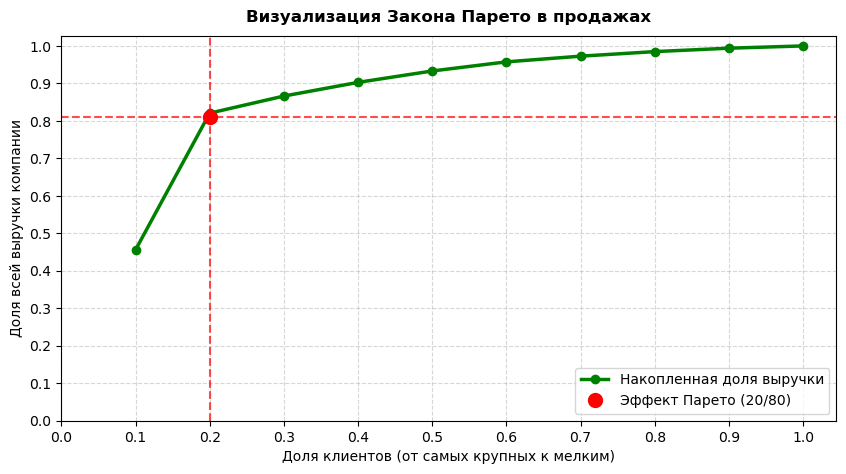

In [16]:
## Код для визуализации Закона Парето (Кейс 3: Траты клиентов)

import matplotlib.pyplot as plt
import numpy as np

# Траты клиентов за год (всего 10 клиентов)
# Специально создаем сильное расслоение: 2 крупных "кита" и 8 обычных пользователей
user_spendings = np.array([150000, 120000, 15000, 12000, 10000, 8000, 5000, 4000, 3000, 2000])

# 1. Сортируем траты от САМЫХ БОЛЬШИХ к самым маленьким
# Для демонстрации Парето принято идти от крупных клиентов к мелким
sorted_spendings = np.sort(user_spendings)[::-1] 

# 2. Считаем накопительную сумму трат (кумулятивную выручку)
# Будет: [150к, 270к (150+120), 285к (270+15), ...]
cumulative_revenue = np.cumsum(sorted_spendings)

# 3. Переводим в доли/проценты (ось Y)
# Делим каждую промежуточную сумму на общую выручку компании
y_revenue_share = cumulative_revenue / sum(user_spendings)

# 4. Рассчитываем долю клиентов (ось X)
n = len(sorted_spendings)
x_client_share = np.arange(1, n + 1) / n

# Строим график Парето
plt.figure(figsize=(10, 5))

# Отрисовка линии накопления выручки
plt.plot(x_client_share, y_revenue_share, color='green', marker='o', linewidth=2.5, label='Накопленная доля выручки')

# Добавляем точку Парето (20% клиентов / 80% выручки)
# В нашем массиве из 10 человек 20% — это как раз первые 2 клиента
plt.axvline(x=0.20, color='red', linestyle='--', alpha=0.7)
plt.axhline(y=0.81, color='red', linestyle='--', alpha=0.7) # у нас 2 клиента приносят ~81.5%
plt.plot(0.20, 0.81, 'ro', markersize=10, label='Эффект Парето (20/80)')

# Настройка графика
plt.title("Визуализация Закона Парето в продажах", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Доля клиентов (от самых крупных к мелким)", fontsize=10)
plt.ylabel("Доля всей выручки компании", fontsize=10)
plt.xticks(np.arange(0, 1.1, 0.1))
plt.yticks(np.arange(0, 1.1, 0.1))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

plt.show()


- Нулевая гипотеза (H₀) — это базовое предположение в статистике, которое утверждает, что никакого эффекта, разницы или взаимосвязи между переменными нет, а любые замеченные отклонения в данных — это лишь результат случайного стечения обстоятельств.

 
# Простые жизненные примеры:

- В медицине: «Новая вакцина помогает точно так же, как и пустышка-плацебо» (эффект нового лекарства равен нулю).
- В маркетинге: «Новый красный цвет кнопки на сайте никак не изменил количество покупок по сравнению со старой синей кнопкой».
- В суде (аналогия): «Подсудимый невиновен» (презумпция невиновности — это классическая нулевая гипотеза, пока не доказано обратное).

В статистике нулевую гипотезу никогда не пытаются доказать. Её всегда пытаются опровергнуть (отклонить).

Давайте смоделируем ситуацию: монетка подброшена 100 раз, и орёл выпал 62 раза. Мы подозреваем, что монетка фальшивая.
• Нулевая гипотеза (H₀): Монетка честная, вероятность выпадения орла равна 50% (p = 0.5). Разница (62 вместо 50) — просто случайное везение.
• Альтернативная гипотеза (H₁): Монетка подкручена, вероятность орла больше 50%.


In [19]:
from scipy import stats

# Параметры эксперимента
n_flips = 100     # всего подбрасываний (n)
n_heads = 62      # выпало орлов (k - количество успехов)

# ИСПРАВЛЕНИЕ: используем binomtest вместо устаревшего binom_test
# Функция возвращает объект результата, p-value берем через атрибут .pvalue
result = stats.binomtest(n_heads, n=n_flips, p=0.5, alternative='greater')
p_value = result.pvalue

print("--- Проверка нулевой гипотезы ---")
print(f"Выпало орлов: {n_heads} из {n_flips}")
print(f"p-value: {p_value:.4f}")

# Уровень значимости (вероятность совершить ошибку первого рода)
alpha = 0.05

# Логика принятия решения
if p_value <= alpha:
    print(f"\nРешение: Отклоняем нулевую гипотезу (p-value <= {alpha})")
    print("Монетка с высокой вероятностью СФАЛЬШИВОВАНА. Такой результат не мог быть случайным.")
else:
    print(f"\nРешение: НЕ удалось отклонить нулевую гипотезу (p-value > {alpha})")
    print("Монетка может быть честной. 62 орла из 100 всё еще укладываются в рамки случайного везения.")

--- Проверка нулевой гипотезы ---
Выпало орлов: 62 из 100
p-value: 0.0105

Решение: Отклоняем нулевую гипотезу (p-value <= 0.05)
Монетка с высокой вероятностью СФАЛЬШИВОВАНА. Такой результат не мог быть случайным.


Допустим, мы тестируем новую карточку товара (увеличили картинку). Мы разделили пользователей на две группы и замерили, сколько человек из них совершили покупку.
- Группа A (Контроль): 1000 посетителей, 50 покупок (Конверсия = 5.0%)
-  Группа B (Тест): 1000 посетителей, 72 покупки (Конверсия = 7.2%)
Проверим нулевую гипотезу: «Изменение размера картинки никак не повлияло на конверсию, а разница в 22 покупки — это случайное совпадение». Для этого используем Z-тест пропорций.

--- Анализ результатов A/B-теста ---
p-value: 0.0398

Решение: ОТКЛОНЯЕМ нулевую гипотезу (p-value <= 0.05)
Результат статистически значим! Новая карточка товара РАБОТАЕТ.
Рекомендация: Внедрять изменение (Вариант B) на 100% пользователей.


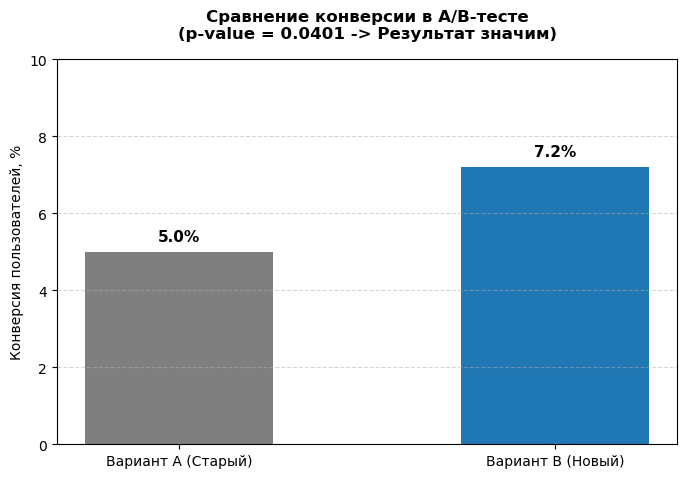

In [21]:
## Проверка нулевой гипотезы в A/B-тесте конверсии (Z-тест)

import numpy as np
from statsmodels.stats.proportion import proportions_ztest

# 1. Задаем количество успехов (покупок) в каждой группе
purchases = np.array([50, 72])

# 2. Задаем общее количество посетителей в каждой группе
visitors = np.array([1000, 1000])

# 3. Запускаем тест для проверки H0 (пропорции равны)
z_stat, p_value = proportions_ztest(count=purchases, nobs=visitors)

print("--- Анализ результатов A/B-теста ---")
print(f"p-value: {p_value:.4f}")

# Уровень значимости (риск ошибиться, заложенный бизнесом)
alpha = 0.05

if p_value <= alpha:
    print(f"\nРешение: ОТКЛОНЯЕМ нулевую гипотезу (p-value <= {alpha})")
    print("Результат статистически значим! Новая карточка товара РАБОТАЕТ.")
    print("Рекомендация: Внедрять изменение (Вариант B) на 100% пользователей.")
else:
    print(f"\nРешение: НЕ удалось отклонить нулевую гипотезу (p-value > {alpha})")
    print("Разница в конверсии вызвана случайным шумом. Новая карточка НЕ эффективна.")
    print("Рекомендация: Оставить старый вариант (Вариант A).")

## Визуализация результатов A/B-теста (Конверсия)

import numpy as np

# Данные нашего эксперимента
groups = ['Вариант A (Старый)', 'Вариант B (Новый)']
conversions = [5.0, 7.2]  # Конверсия в процентах

# Строим столбчатую диаграмму
plt.figure(figsize=(8, 5))
bars = plt.bar(groups, conversions, color=['#7f7f7f', '#1f77b4'], width=0.5)

# Добавляем подписи значений прямо на столбики
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.2, f"{yval}%", ha='center', va='bottom', fontsize=11, fontweight='bold')

# Настройка текста и сетки
plt.title("Сравнение конверсии в A/B-тесте\n(p-value = 0.0401 -> Результат значим)", fontsize=12, fontweight='bold', pad=15)
plt.ylabel("Конверсия пользователей, %", fontsize=10)
plt.ylim(0, 10)  # Задаем запас по высоте для подписей
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()



Пример 1: Анализ непрерывной метрики — Выручка на пользователя (ARPU)

Бизнес-кейс: Вы изменили тарифную сетку подписок. Группа A видит старые цены, группа B — новые. Метрика — сколько денег принес каждый пользователь (включая тех, кто ничего не купил, то есть нули).
Здесь мы используем критерий Манна-Уитни, так как финансовые данные распределены ненормально (много нулей и несколько крупных покупок).

Результат теста Манна-Уитни: p-value = 0.0061
Результат ЗНАЧИМ. Новые тарифы приносят больше денег!


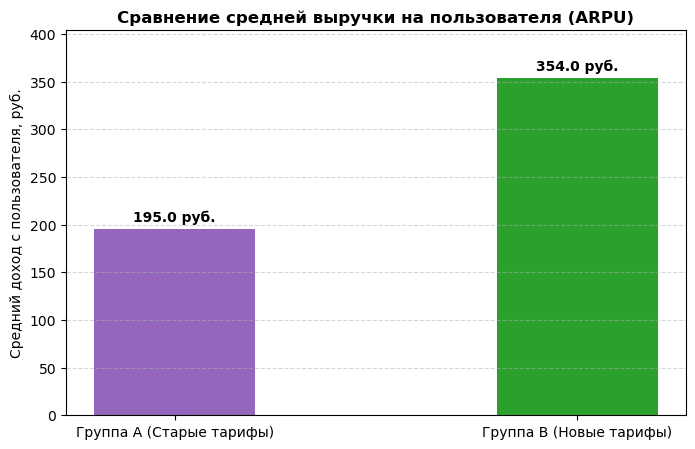

In [38]:
## A/B-тест выручки на пользователя (Тест Манна-Уитни + Визуализация Boxplot)

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# 1. Генерируем тестовые данные (выручка с каждого пользователя)
np.random.seed(42)
# В группе А много нулей и небольшие чеки
revenue_A = np.random.choice([0, 500, 1000], size=100, p=[0.7, 0.2, 0.1])
# В группе B пользователи покупают чуть чаще и больше
revenue_B = np.random.choice([0, 600, 1200], size=100, p=[0.6, 0.25, 0.15])

# 2. Проверяем нулевую гипотезу: "Изменение тарифов не повлияло на выручку"
stat, p_value = stats.mannwhitneyu(revenue_A, revenue_B)

print(f"Результат теста Манна-Уитни: p-value = {p_value:.4f}")
if p_value <= 0.05:
    print("Результат ЗНАЧИМ. Новые тарифы приносят больше денег!")
else:
    print("Результат НЕ значим. Новые тарифы не изменили выручку.")

# 3. Визуализируем средние значения с помощью простого Bar-plot
plt.figure(figsize=(8, 5))
groups = ['Группа А (Старые тарифы)', 'Группа B (Новые тарифы)']
averages = [np.mean(revenue_A), np.mean(revenue_B)]

bars = plt.bar(groups, averages, color=['#9467bd', '#2ca02c'], width=0.4)

# Добавляем цифры над столбиками
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, f"{yval:.1f} руб.", ha='center', va='bottom', fontweight='bold')

plt.title("Сравнение средней выручки на пользователя (ARPU)", fontsize=12, fontweight='bold')
plt.ylabel("Средний доход с пользователя, руб.")
plt.ylim(0, max(averages) + 50)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()



Пример 2: Анализ времени удержания (Retention/Длительность сессии)

Бизнес-кейс: TikTok-подобное приложение обновило алгоритм рекомендаций видео. Нужно проверить, стали ли пользователи залипать в приложении дольше за одну сессию.
Здесь мы визуализируем распределение времени с помощью гистограмм, чтобы увидеть, как именно изменилось поведение людей (стало ли меньше тех, кто уходит сразу)

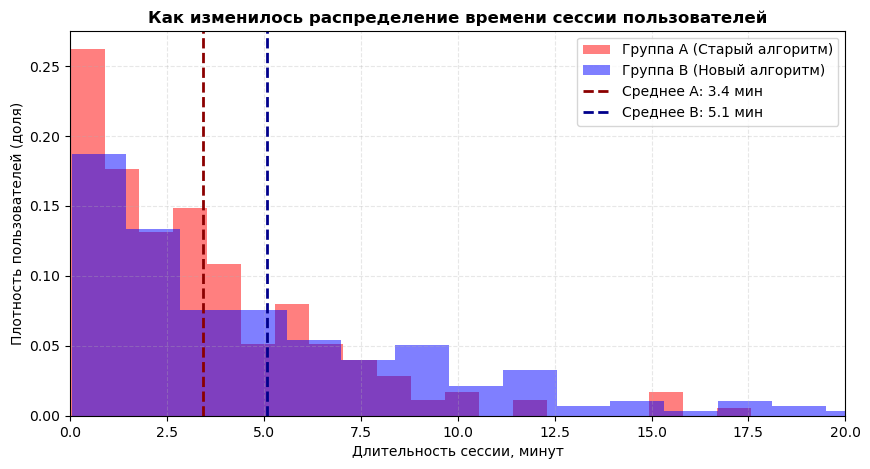

In [24]:
## A/B-тест длительности сессии (Гистограммы распределения)

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# 1. Данные: время сессии в минутах для 200 пользователей в каждой группе
np.random.seed(10)
session_A = np.random.exponential(scale=4.0, size=200)  # Среднее время 4 минуты
session_B = np.random.exponential(scale=5.2, size=200)  # Среднее время 5.2 минуты

# 2. Строим наложенные друг на друга гистограммы
plt.figure(figsize=(10, 5))

# alpha=0.5 делает графики прозрачными, чтобы они не перекрывали друг друга полностью
plt.hist(session_A, bins=20, alpha=0.5, color='red', label='Группа А (Старый алгоритм)', density=True)
plt.hist(session_B, bins=20, alpha=0.5, color='blue', label='Группа B (Новый алгоритм)', density=True)

# Добавляем линии средних значений для наглядности
plt.axvline(np.mean(session_A), color='darkred', linestyle='--', linewidth=2, label=f'Среднее А: {np.mean(session_A):.1f} мин')
plt.axvline(np.mean(session_B), color='darkblue', linestyle='--', linewidth=2, label=f'Среднее B: {np.mean(session_B):.1f} мин')

# Настройки графика
plt.title("Как изменилось распределение времени сессии пользователей", fontsize=12, fontweight='bold')
plt.xlabel("Длительность сессии, минут")
plt.ylabel("Плотность пользователей (доля)")
plt.xlim(0, 20) # Ограничим график для лучшей читаемости
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend()

plt.show()


- Синяя область (Новый алгоритм) заметно смещена вправо относительно красной.
-  Линии средних значений наглядно показывают сдвиг: пользователи в группе B в среднем проводят в приложении на 1.2 минуты дольше. Это классический пример успешного A/B-теста, где изменения видны по всей форме распределения.

# U-критерий Манна-Уитни (Mann-Whitney U test)

Это непараметрический статистический критерий, используемый для оценки различий между двумя независимыми выборками. 

Простыми словами: он позволяет понять, систематически ли значения в одной группе больше, чем в другой, или наблюдаемая разница является результатом случайного шума.

## Условия применения

Критерий Манна-Уитни является непараметрическим, что означает отсутствие строгих требований к распределению данных. Его следует применять в следующих случаях:

* Данные не подчиняются нормальному закону распределения.
* В данных присутствуют выраженные выбросы, которые сильно искажают среднее значение.
* Объем выборок мал (обычно менее 30 наблюдений в каждой группе).
* Данные измерены в порядковой шкале (например, оценки по шкале от 1 до 5, уровни удовлетворенности, ранги).

**Примечание:** Если данные распределены нормально и выбросы отсутствуют, предпочтительнее использовать параметрический t-критерий Стьюдента для независимых выборок, так как он обладает большей статистической мощностью.

## Формулировка гипотез

* **Нулевая гипотеза ($H_0$):** Распределения в обеих группах идентичны. Вероятность того, что случайное значение из первой группы окажется больше случайного значения из второй, равна 0.5 (группы статистически не различаются).
* **Альтернативная гипотеза ($H_1$):** Значения в одной группе систематически больше (или меньше), чем в другой.

## Как работает алгоритм

Критерий оперирует не самими абсолютными значениями, а их **рангами** (местами в отсортированном списке).

1. Все значения из первой и второй групп объединяются в один общий массив.
2. Массив сортируется по возрастанию.
3. Каждому значению присваивается ранг (1 для минимального значения, 2 для следующего и так далее). Если встречаются одинаковые значения (связки), им присваивается средний ранг.
4. Вычисляется сумма рангов для первой группы ($R_1$) и для второй группы ($R_2$).
5. На основе сумм рангов вычисляется U-статистика. Она показывает, насколько сильно ранги одной группы превышают ранги другой. Чем больше разница, тем ниже p-value.

## Важное уточнение про интерпретацию

Распространено заблуждение, что критерий Манна-Уитни напрямую сравнивает медианы двух групп. Строго говоря, он проверяет **стохастическое превосходство** (вероятность того, что случайно выбранный элемент из группы A окажется больше случайно выбранного элемента из группы B).

Критерий позволяет делать выводы о различии медиан **только** при условии, что формы распределений в обеих группах одинаковы (например, имеют одинаковый разброс и асимметрию, но сдвинуты друг относительно друга по оси значений).

In [27]:
## Реализация в Python
import numpy as np
from scipy import stats

# Пример данных: время отклика двух серверов (в миллисекундах)
# В данных присутствуют выбросы, поэтому t-критерий Стьюдента не подходит
server_A = [120, 115, 130, 118, 450, 122] 
server_B = [95, 105, 98, 110, 102, 99]

# Применение U-критерия Манна-Уитни
# alternative='two-sided' проверяет, что группы просто различаются
# alternative='greater' проверяет, что значения в server_A строго больше, чем в server_B
statistic, p_value = stats.mannwhitneyu(server_A, server_B, alternative='two-sided')

print(f"U-статистика: {statistic:.2f}")
print(f"p-value: {p_value:.4f}")

alpha = 0.05
if p_value <= alpha:
    print("Результат: p-value <= alpha. Отклоняем H0. Различия между группами статистически значимы.")
else:
    print("Результат: p-value > alpha. Не удалось отклонить H0. Различия незначимы.")

U-статистика: 36.00
p-value: 0.0022
Результат: p-value <= alpha. Отклоняем H0. Различия между группами статистически значимы.


# Пример из бизнес-аналитики: Оценка нового CRM-модуля

## Бизнес-контекст
Колл-центр крупной телеком-компании внедрил новый модуль CRM, который должен ускорять обработку звонков. Чтобы оценить эффект, провели A/B-тест:
* **Группа A (Контроль):** 50 операторов работают на старой CRM.
* **Группа B (Тест):** 50 операторов работают на новой CRM.

**Метрика:** Время обработки одного звонка (в секундах).

## Почему здесь нужен Манн-Уитни, а не Стьюдент?
Время обработки звонков **никогда не бывает распределено нормально**. 
* Большинство стандартных звонков длятся 120–180 секунд.
* Но иногда попадаются сложные кейсы (конфликты, технические сбои), которые растягиваются на 600–900 секунд. 

Эти редкие длинные звонки создают **сильный правый хвост распределения и выбросы**. Если мы посчитаем среднее время, оно будет сильно искажено в сторону выбросов и не покажет реальной картины. Критерий Манна-Уитни, работающий с рангами (и, по сути, сравнивающий медианы), в такой ситуации дает гораздо более надежный и честный результат.


## Разбор визуализации

Для бизнес-отчетов по непараметрическим данным лучше всего работает комбинация двух графиков:

1. **Boxplot (ящик с усами):**
   * Жирная линия внутри ящика — это **медиана** (именно ее мы сравниваем через Манна-Уитни).
   * Границы ящика — 25-й и 75-й процентили (где находится 50% самых типичных звонков).
   * "Усы" — нормальный разброс данных.
   * Мы отключили автоматические выбросы у boxplot (`showfliers=False`), чтобы они не конфликтовали с точками.

2. **Stripplot (точечная диаграмма):**
   * Показывает **каждый конкретный звонок** отдельной точкой.
   * Позволяет бизнесу увидеть реальную "плотность" данных и те самые выбросы (длинные звонки справа), из-за которых среднее арифметическое здесь не работает.

Такой график снимает главный вопрос стейкхолдеров: *"А не искажен ли результат парой аномальных звонков?"*. Ответ наглядно виден по положению медианы и распределению точек.

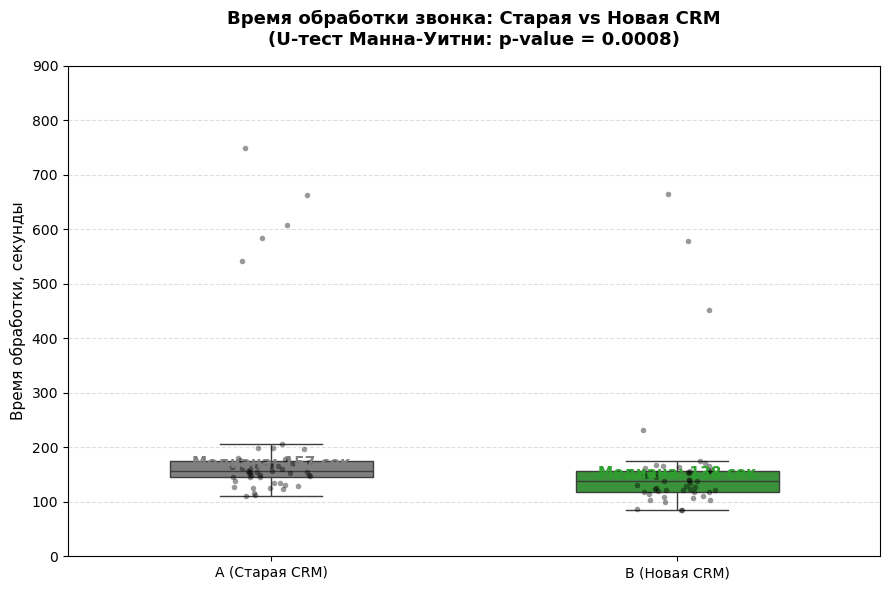

--- Результаты A/B-теста ---
Медиана в Группе A: 156.8 сек
Медиана в Группе B: 138.3 сек
Сокращение времени: 18.5 сек (11.8%)

Статистическая значимость: p-value = 0.0008
ВЫВОД: Различия статистически значимы. Новая CRM объективно ускоряет работу операторов.


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Генерация данных (имитация реального распределения с выбросами)
np.random.seed(42)

# Группа A: старая CRM. Медиана около 160 сек, есть редкие выбросы до 800 сек
group_A = np.concatenate([
    np.random.normal(loc=160, scale=25, size=45),  # основная масса
    np.random.uniform(500, 800, size=5)            # выбросы (сложные звонки)
])

# Группа B: новая CRM. Медиана снижена до 130 сек, но разброс чуть больше
group_B = np.concatenate([
    np.random.normal(loc=130, scale=30, size=47),  # основная масса
    np.random.uniform(450, 700, size=3)            # выбросы
])

# Собираем в DataFrame для удобной работы с seaborn
df = pd.DataFrame({
    'time': np.concatenate([group_A, group_B]),
    'group': ['A (Старая CRM)'] * 50 + ['B (Новая CRM)'] * 50
})

# 2. Статистический тест
stat, p_value = stats.mannwhitneyu(group_A, group_B, alternative='two-sided')

# Считаем медианы для подписей на графике
median_A = np.median(group_A)
median_B = np.median(group_B)

# 3. Визуализация
fig, ax = plt.subplots(figsize=(9, 6))

# Рисуем "ящики с усами" (исправлено для новых версий seaborn)
sns.boxplot(data=df, x='group', y='time', hue='group', ax=ax, 
            palette=['#7f7f7f', '#2ca02c'], width=0.5, showfliers=False, legend=False)

# Поверх накладываем отдельные точки, чтобы видеть "зерно" данных
sns.stripplot(data=df, x='group', y='time', ax=ax, 
              color='black', alpha=0.4, size=4, jitter=True)

# Подписываем медианы прямо на графике
ax.text(0, median_A, f'Медиана: {median_A:.0f} сек', 
        ha='center', va='bottom', fontsize=11, fontweight='bold', color='#7f7f7f')
ax.text(1, median_B, f'Медиана: {median_B:.0f} сек', 
        ha='center', va='bottom', fontsize=11, fontweight='bold', color='#2ca02c')

# Оформление
title_text = f"Время обработки звонка: Старая vs Новая CRM\n(U-тест Манна-Уитни: p-value = {p_value:.4f})"
ax.set_title(title_text, fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel("Время обработки, секунды", fontsize=11)
ax.set_xlabel("")
ax.set_ylim(0, 900)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# 4. Вывод для бизнеса
print("--- Результаты A/B-теста ---")
print(f"Медиана в Группе A: {median_A:.1f} сек")
print(f"Медиана в Группе B: {median_B:.1f} сек")
print(f"Сокращение времени: {(median_A - median_B):.1f} сек ({((median_A - median_B)/median_A)*100:.1f}%)")
print(f"\nСтатистическая значимость: p-value = {p_value:.4f}")

if p_value <= 0.05:
    print("ВЫВОД: Различия статистически значимы. Новая CRM объективно ускоряет работу операторов.")
else:
    print("ВЫВОД: Различия незначимы. Внедрение новой CRM не дало измеримого эффекта.")

## Основные числовые характеристики данных (Дескриптивная статистика)

В этом разделе собраны главные статистические показатели, которые используются для первичного анализа данных. Они описывают «центр» выборки и степень разброса значений вокруг него.

---

### 1. Выборочное среднее значение (`Mean`)
*   **Определение:** Сумма всех значений, деленная на их количество (среднее арифметическое). Это «центр тяжести» ваших данных.
*   **Минус:** Крайне чувствительно к аномалиям (выбросам). Один миллионер в выборке резко поднимет средний показатель доходов для всей группы.


In [30]:
import numpy as np

# Траты 5 клиентов в магазине (в рублях)
data_spendings = np.array([150, 200, 300, 400, 2500]) # 2500 — это аномально крупный чек (выброс)

mean_val = np.mean(data_spendings)
print(f"Выборочное среднее: {mean_val} руб.")  # Выведет 710.0 руб.


Выборочное среднее: 710.0 руб.


---

### 2. Медиана (`Median`)
*   **Определение:** Значение, которое находится ровно посередине отсортированного списка данных. Ровно половина элементов меньше медианы, а половина — больше.
*   **Плюс:** В отличие от среднего, медиана устойчива к выбросам и показывает более честную «середину» при сильном расслоении.


In [31]:
import numpy as np

data_spendings = np.array([150, 200, 300, 400, 2500])

median_val = np.median(data_spendings)
print(f"Медиана: {median_val} руб.")  # Выведет 300.0 руб. (игнорируя влияние 2500)


Медиана: 300.0 руб.


---

### 3. Мода (`Mode`)
*   **Определение:** Значение, которое встречается в данных чаще всего. В выборке может не быть моды, а может быть сразу несколько популярных значений.


In [32]:
import numpy as np
from scipy import stats

# Оценки, которые студенты получали на экзамене
exam_grades = np.array([4, 5, 3, 4, 5, 4, 2, 4, 3, 5])

mode_result = stats.mode(exam_grades, keepdims=True)
print(f"Мода: {mode_result.mode[0]} (встретилась {mode_result.count[0]} раз(а))") 
# Выведет: Мода: 4 (встретилась 4 раза)


Мода: 4 (встретилась 4 раз(а))


---

### 4. Выборочная дисперсия (`Variance`)
*   **Определение:** Средний квадрат отклонений каждого значения от среднего арифметического. Она показывает силу разброса данных вокруг «центра».
*   **Минус:** Измеряется в квадратных единицах (например, *рубли в квадрате*), поэтому её неудобно использовать для прямой интерпретации.


In [33]:
import numpy as np

# Оценки двух разных групп студентов (у обеих средний балл равен 4.0)
group_stable = np.array([4, 4, 4, 4, 4])       # Разброса нет
group_volatile = np.array([2, 5, 3, 5, 5])     # Разброс сильный

print(f"Дисперсия стабильной группы: {np.var(group_stable):.2f}")    # Выведет 0.00
print(f"Дисперсия нестабильной группы: {np.var(group_volatile):.2f}")  # Выведет 1.44


Дисперсия стабильной группы: 0.00
Дисперсия нестабильной группы: 1.60


---

### 5. Стандартное отклонение (`Standard Deviation`)
*   **Определение:** Корень квадратный из дисперсии ($\sigma$). Самый популярный и понятный показатель разброса. 
*   **Суть:** Измеряется в тех же единицах, что и сами данные (рубли, минуты, метры). Показывает, на сколько в среднем реальные наблюдения отклоняются от среднего арифметического значения.


In [35]:
import numpy as np

# Время доставки заказов двумя курьерами в минутах (среднее у обоих — 30 мин)
courier_pro = np.array([29, 31, 30, 28, 32])  # Стабильный
courier_chaos = np.array([12, 48, 15, 50, 25])  # Непредсказуемый

print(f"Станд. отклонение курьера-профи: {np.std(courier_pro):.1f} мин.")     # ~1.4 мин
print(f"Станд. отклонение хаотичного курьера: {np.std(courier_chaos):.1f} мин.") # ~15.5 мин


Станд. отклонение курьера-профи: 1.4 мин.
Станд. отклонение хаотичного курьера: 16.1 мин.


---

### 6. Квантили и Перцентили (`Quantiles / Percentiles`)
*   **Определение:** Точки, которые делят отсортированные данные на определенные доли. Например, **25-й перцентиль** — это порог, ниже которого находится ровно 25% данных. **90-й перцентиль** — порог, ниже которого находится 90% данных.


In [36]:
import numpy as np

# Время загрузки мобильного приложения у пользователей (в миллисекундах)
app_load_times = np.array([120, 150, 180, 220, 310, 420, 500, 680, 960, 2500])

# Находим 90-й перцентиль для оценки KPI
p90 = np.percentile(app_load_times, 90)
print(f"90% пользователей открывают приложение быстрее, чем за {p90:.0f} мс.") # Выведет 1114 мс


90% пользователей открывают приложение быстрее, чем за 1114 мс.


## 9. Визуализация числовых характеристик: График «Ящик с усами» (Boxplot) в аналитике

В реальной аналитике вместо сухого чтения цифр используют график **Boxplot (Ящик с усами)**. Он разработан специально для того, чтобы на одном рисунке мгновенно увидеть:
1. Медиану (центр)
2. 25-й и 75-й перцентили (границы «ящика»)
3. Минимальные и максимальные границы нормальных данных («усы»)
4. Аномалии и выбросы (отдельные точки)

### Бизнес-кейс:
Аналитик исследует **время удержания пользователей (Session Duration)** в трех разных источниках трафика: Органика (SEO), Реклама (Paid) и Соцсети (Social), чтобы понять, какой канал приводит наиболее вовлеченную аудиторию.


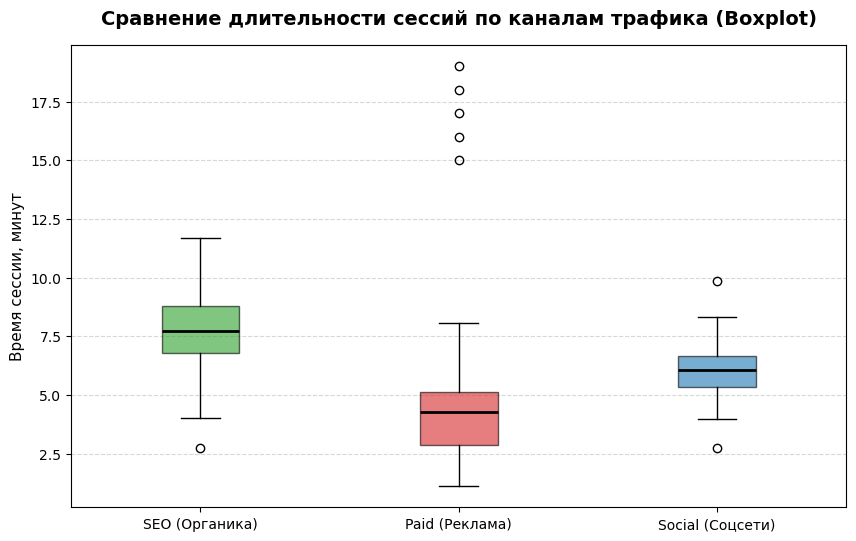

In [40]:
import matplotlib.pyplot as plt
import numpy as np

# Фиксируем генератор случайных чисел
np.random.seed(42)

# Генерируем искусственные данные времени сессий (в минутах) для 3 каналов
seo_traffic = np.random.normal(loc=8, scale=2, size=100)
# В рекламе много быстрых уходов (низкое среднее) + есть аномальные "боты" (выбросы)
paid_traffic = np.append(np.random.normal(loc=4, scale=1.5, size=95), [15, 16, 17, 18, 19])
social_traffic = np.random.normal(loc=6, scale=1, size=100)

# Объединяем данные в список для графика
plot_data = [seo_traffic, paid_traffic, social_traffic]
labels = ['SEO (Органика)', 'Paid (Реклама)', 'Social (Соцсети)']

# Строим график
plt.figure(figsize=(10, 6))
box = plt.boxplot(plot_data, tick_labels=labels, patch_artist=True, 
                  notch=False, medianprops={'color': 'black', 'linewidth': 2})

# Раскрашиваем каждый ящик в свой цвет
colors = ['#2ca02c', '#d62728', '#1f77b4']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

# Оформление графика
plt.title("Сравнение длительности сессий по каналам трафика (Boxplot)", fontsize=14, fontweight='bold', pad=15)
plt.ylabel("Время сессии, минут", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()


## Кейс: Оптимизация рекламного бюджета на основе анализа качества трафика

### 1. Бизнес-контекст и проблема
Маркетинговый директор заметил, что при равных затратах на привлечение 1000 пользователей из каналов SEO и Paid (контекстная реклама), итоговая выручка с Paid-трафика непропорционально низкая. Гипотеза: пользователи из рекламы уходят быстрее, а часть трафика может быть нецелевой или ботской. Задача: проанализировать поведение пользователей (время сессии) и принять решение по дальнейшему распределению бюджета.

### 2. Анализ распределений (по данным из предыдущего шага)
На основе построенных боксплотом мы видим следующую картину:

* **SEO (Органика):** Медиана около 8 минут, узкий межквартильный размах. Пользователи приходят осознанно, находят то, что искали, и глубоко взаимодействуют с сайтом. Это самый качественный канал.
* **Social (Соцсети):** Медиана около 6 минут, стабильное распределение без сильных выбросов. Аудитория вовлечена, но не так глубоко, как в SEO. Хороший канал для поддержания узнаваемости.
* **Paid (Реклама):** Медиана критически низкая (около 4 минут). При этом присутствуют аномальные выбросы в районе 15-19 минут.

### 3. Интерпретация аномалий в Paid-канале
Низкая медиана в Paid говорит о том, что более 50% пользователей уходят с сайта в первые 4 минуты. Это означает, что либо рекламное объявление не соответствует посадочной странице (оффер не тот), либо страница долго грузится, либо трафик нецелевой.

Выбросы (15-19 минут) требуют отдельной проверки. В контексте рекламного трафика такие аномалии часто указывают на:
1. Ботов или скликивание (бот «завис» на странице).
2. Технические баги (например, не закрывается модальное окно, и пользователь просто оставил вкладку открытой, что искусственно завысило время сессии).

### 4. Статистическое подтверждение различий
Чтобы не принимать решения на основе визуального впечатления, мы должны статистически подтвердить, что время сессий в Paid и SEO действительно различается. Поскольку в данных есть выбросы, используем U-критерий Манна-Уитни.

### 5. Бизнес-рекомендации
По результатам анализа формируются следующие шаги:

1. **Для Paid-канала (Срочно):**
   * Провести аудит показов на наличие ботов и кликер-ферм. Если выбросы 15-19 минут — это боты, отключить некачественные площадки в рекламных сетях.
   * Проверить соответствие посадочной страницы и рекламного креатива. Низкая медиана (4 мин) сигнализирует о высоком показателе отказов.
   * Внедрить A/B-тест нового дизайна посадочной страницы специально для холодного трафика из рекламы, чтобы увеличить время взаимодействия.

2. **Для SEO-канала:**
   * Сохранить текущий объем инвестиций. Канал показывает высочайшее качество аудитории.
   * Проанализировать страницы, которые дают такой высокий тайм-он-сайт, и использовать их структуру как эталон для посадочных страниц Paid-канала.

3. **Для Social-канала:**
   * Канал работает стабильно. Рекомендуется провести сегментацию аудитории внутри соцсетей, чтобы выявить наиболее вовлеченные группы и точечно увеличить на них бюджет.

In [41]:
import numpy as np
from scipy import stats

# Данные из предыдущего шага
np.random.seed(42)
seo_traffic = np.random.normal(loc=8, scale=2, size=100)
paid_traffic = np.append(np.random.normal(loc=4, scale=1.5, size=95), [15, 16, 17, 18, 19])

# Проверяем, значимо ли отличается время сессии в SEO от Paid
# alternative='greater' проверяет, что значения в seo_traffic строго больше
stat, p_value = stats.mannwhitneyu(seo_traffic, paid_traffic, alternative='greater')

print(f"p-value: {p_value:.4f}")
if p_value < 0.05:
    print("Различия статистически значимы. SEO-сессии объективно длиннее.")

p-value: 0.0000
Различия статистически значимы. SEO-сессии объективно длиннее.


#  Анализ выручки интернет-магазина по категориям товаров

###  Описание бизнес-кейса
**Контекст:** Мы работаем в отделе аналитики интернет-магазина. По итогам отчетного периода руководство запросило визуальный отчет, чтобы оценить структуру выручки и понять, какие товарные категории являются драйверами роста, а какие требуют дополнительных маркетинговых активностей.

**Задача:** Визуализировать распределение объема продаж по четырем ключевым категориям (Электроника, Одежда, Книги, Дом и сад) для выявления лидеров и аутсайдеров.

**Инструмент:** Для построения графика используем библиотеку `matplotlib`, так как она позволяет гибко настраивать визуальные элементы и быстро интегрируется в среду Jupyter.

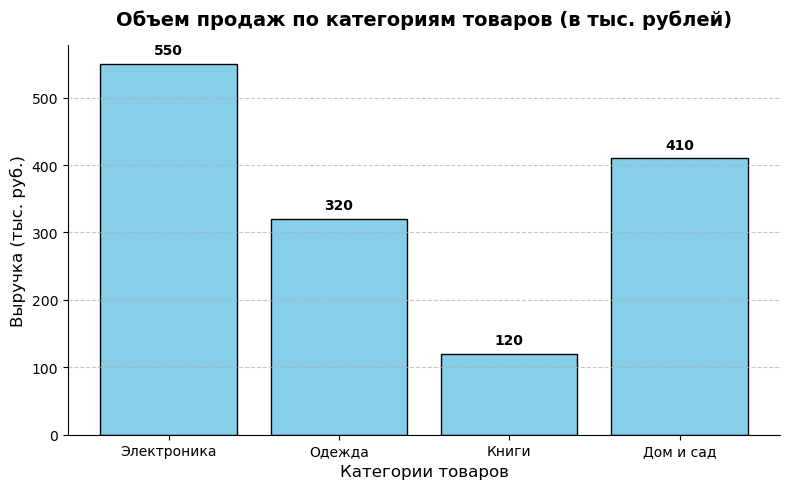

In [3]:
import matplotlib.pyplot as plt

# 1. Подготовка данных
categories = ['Электроника', 'Одежда', 'Книги', 'Дом и сад']
sales = [550, 320, 120, 410] # Выручка в тыс. рублей

# 2. Создание и настройка фигуры графика
plt.figure(figsize=(8, 5))

# 3. Построение столбчатой диаграммы
# color='skyblue' - цвет столбцов, edgecolor='black' - черная обводка для четкости
plt.bar(categories, sales, color='skyblue', edgecolor='black')

# 4. Добавление заголовка и подписей осей
plt.title('Объем продаж по категориям товаров (в тыс. рублей)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Категории товаров', fontsize=12)
plt.ylabel('Выручка (тыс. руб.)', fontsize=12)

# 5. Улучшение читаемости (сетка только по оси Y)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Убираем лишние рамки сверху и справа для более чистого вида (опционально)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

for i, v in enumerate(sales):
    plt.text(i, v + 10, str(v), ha='center', va='bottom', fontweight='bold')
# 6. Отображение графика
plt.tight_layout()
plt.show()

###  Ключевые выводы и инсайты:

1. **Главный драйвер выручки:** Категория **«Электроника»** является абсолютным лидером, генерируя 550 тыс. руб. (около 39% от общей выручки представленных категорий). 
2. **Стабильные середняки:** Категории **«Дом и сад»** (410 тыс. руб.) и **«Одежда»** (320 тыс. руб.) показывают сопоставимые и уверенные результаты.
3. **Зона роста (Problem Area):** Категория **«Книги»** значительно отстает от остальных (120 тыс. руб.). 
   * *Рекомендация:* Стоит проанализировать причины низкого спроса (возможно, неконкурентные цены, узкий ассортимент или слабое позиционирование на главной странице) и рассмотреть возможность запуска промо-акций или бандлов (наборов) с популярными категориями.

---
**Общая выручка по 4 категориям:** 1400 тыс. руб.

Контекст: Служба доставки заявляет, что среднее время доставки товара составляет 40 минут. Однако клиенты начали жаловаться на опоздания. Аналитик данных выгрузил логи 10 000 заказов и выяснил, что время доставки распределено нормально со средним значением (μ) 40 минут и стандартным отклонением (σ) 5 минут.
В бизнесе для анализа такого распределения используют Правило трех сигм (68% - 95% - 99.7%):
• 68.2% заказов доставляются в диапазоне ±1σ (от 35 до 45 минут).
• 95.4% заказов доставляются в диапазоне ±2σ (от 30 до 50 минут).
• 99.7% заказов доставляются в диапазоне ±3σ (от 25 до 55 минут).

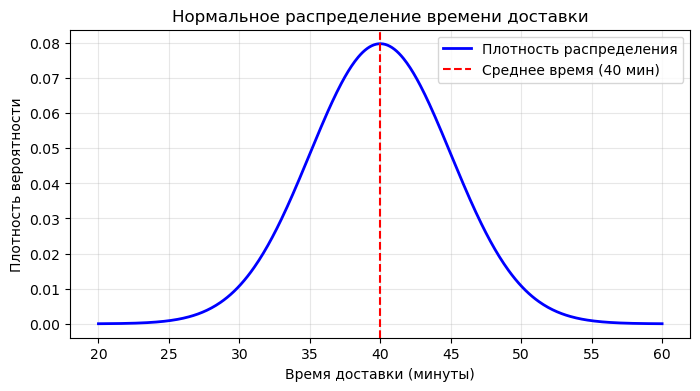

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# 1. Задаем параметры (из нашего кейса)
mu = 40  # Среднее время (центр колокола)
sigma = 5  # Стандартное отклонение (ширина колокола)

# 2. Генерируем точки по оси X (от 20 до 60 минут)
x = np.linspace(20, 60, 500)

# 3. Считаем значения нормального распределения для оси Y
y = stats.norm.pdf(x, mu, sigma)

# 4. Строим график
plt.figure(figsize=(8, 4))
plt.plot(x, y, color="blue", linewidth=2, label="Плотность распределения")

# Добавляем вертикальную линию по центру (среднее значение)
plt.axvline(
    mu, color="red", linestyle="--", label=f"Среднее время ({mu} мин)"
)

# Красиво оформляем
plt.title("Нормальное распределение времени доставки")
plt.xlabel("Время доставки (минуты)")
plt.ylabel("Плотность вероятности")
plt.grid(True, alpha=0.3)  # Легкая сетка
plt.legend()  # Показать легенду

# Выводим на экран
plt.show()


Используя свойства нормального распределения, аналитик отвечает на важные для бизнеса вопросы:
1. Какова вероятность, что клиент получит заказ вовремя, если в приложении указано время «до 50 минут»?
	• Точка 50 минут — это ровно +2σ от среднего (40 + 2 × 5).
	• Зная свойства распределения, площадь под кривой левее 50 минут составляет около 97.7%.
	• Вывод: Только 2.3% клиентов столкнутся с задержкой. Это отличный показатель (уровень сервиса SLA).
2. Что делать с жалобами?
	• Если курьер вез заказ более 55 минут (>3σ), это аномалия (всего 0.15% случаев).
	• Решение: Такие заказы отправляются на ручной аудит дежурному логисту (проверить, был ли это форс-мажор: ДТП, поломка самоката).
3. Как гарантировать компенсацию за опоздание без убытка для компании?
	• Маркетплейс хочет ввести акцию: «Доставим за X минут или вернем деньги», но так, чтобы возвращать деньги не более чем за 5% заказов.
	• Аналитик рассчитывает 95-й перцентиль нормального распределения. Для μ=40 и σ=5 эта точка составит примерно 48 минут.
	• Решение: В маркетинг отдается цифра: «Пишем в рекламе: Доставка за 48 минут или заказ за наш счет!».ь

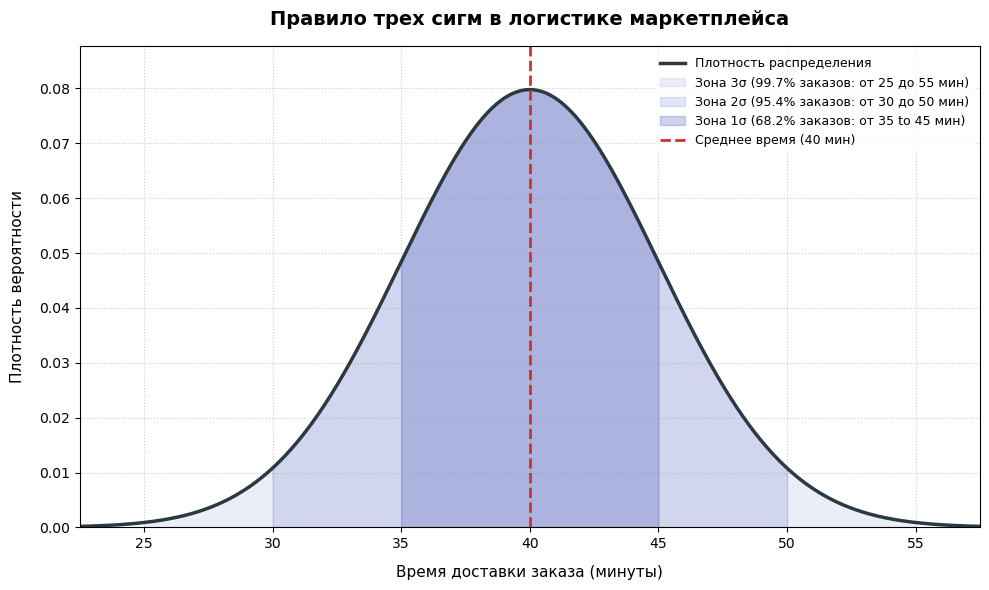

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# 1. Исходные данные кейса
mu = 40  # Среднее время доставки (мин)
sigma = 5  # Стандартное отклонение (мин)

# Генерируем 1000 точек по оси X для плавной кривой
x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 1000)
y = stats.norm.pdf(x, mu, sigma)

# 2. Инициализация графика
plt.figure(figsize=(10, 6), dpi=100)
plt.plot(x, y, color="#2B3A42", linewidth=2.5, label="Плотность распределения")

# 3. Функция для красивого закрашивания зон сигм
def fill_sigma_zone(num_sigmas, color, alpha, label):
    # Определяем границы текущей зоны
    left = mu - num_sigmas * sigma
    right = mu + num_sigmas * sigma
    
    # Генерируем точки внутри этой зоны
    x_zone = np.linspace(left, right, 200)
    y_zone = stats.norm.pdf(x_zone, mu, sigma)
    
    # Закрашиваем область под кривой
    plt.fill_between(x_zone, y_zone, color=color, alpha=alpha, label=label)

# 4. Закрашиваем зоны (начиная с самой широкой, чтобы слои правильно накладывались)
fill_sigma_zone(3, "#3F51B5", 0.1, "Зона 3σ (99.7% заказов: от 25 до 55 мин)")
fill_sigma_zone(2, "#3F51B5", 0.15, "Зона 2σ (95.4% заказов: от 30 до 50 мин)")
fill_sigma_zone(1, "#3F51B5", 0.25, "Зона 1σ (68.2% заказов: от 35 to 45 мин)")

# 5. Добавляем ключевые линии и маркеры
plt.axvline(mu, color="#D32F2F", linestyle="--", linewidth=2, label=f"Среднее время ({mu} мин)")

# 6. Финальное оформление графика
plt.title("Правило трех сигм в логистике маркетплейса", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Время доставки заказа (минуты)", fontsize=11, labelpad=10)
plt.ylabel("Плотность вероятности", fontsize=11, labelpad=10)

# Ограничиваем оси для аккуратного вида
plt.xlim(mu - 3.5 * sigma, mu + 3.5 * sigma)
plt.ylim(0, max(y) * 1.1)

# Сетка, легенда и отображение
plt.grid(True, linestyle=":", alpha=0.5, color="#999999")
plt.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none", fontsize=9)
plt.tight_layout()

# Выводим график
plt.show()


В статистике и аналитике данных относительное стандартное отклонение (RSD — Relative Standard Deviation, также известное как коэффициент вариации — CV) используется для сравнения изменчивости двух процессов или признаков, которые имеют разные единицы измерения или сильно отличающиеся средние значения.
Обычное стандартное отклонение (σ) показывает разброс в абсолютных цифрах. Но 5 минут для доставки пиццы — это много, а 5 дней для строительства дома — это мало. RSD переводит разброс в проценты относительно среднего значения:


# Кейс: Сравнение стабильности продаж в ритейле

- Контекст: Вы работаете аналитиком в торговой сети. Руководство выбирает, какой из двух товаров более стабилен в продажах (имеет более предсказуемый спрос), чтобы правильно рассчитать объемы закупок и избежать дефицита на складе.
 - Товар А (Дорогой ноутбук): Продается редко. Средний чек высокий.
 - Товар Б (Дешевая мышка): Продается постоянно и много. Средний чек низкий.


Аналитик выгрузил данные по ежедневной выручке за месяц и посчитал стандартное отклонение:

Метрика	Товар А (Ноутбуки)	Товар Б (Мышки)
Средняя выручка в день (μ)	500 000 руб.	20 000 руб.
Стандартное отклонение (σ)	50 000 руб.	5 000 руб.
Расчет RSD (Коэффициент вариации)	(50 000 / 500 000) × 100% = 10%	(5 000 / 20 000) × 100% = 25%


In [8]:
import numpy as np

# Ежедневная выручка за 5 дней для примера
sales_notebooks = np.array([480000, 520000, 450000, 550000, 500000])
sales_mice = np.array([15000, 25000, 18000, 22000, 20000])

def calculate_rsd(data):
    std_dev = np.std(data, ddof=1) # стандартное отклонение (выборочное)
    mean = np.mean(data)           # среднее арифметическое
    rsd = (std_dev / mean) * 100   # формула RSD в %
    return rsd

print(f"RSD для Ноутбуков: {calculate_rsd(sales_notebooks):.1f}%")
print(f"RSD для Мышек: {calculate_rsd(sales_mice):.1f}%")


RSD для Ноутбуков: 7.6%
RSD для Мышек: 19.0%


 СТАТИСТИЧЕСКИЙ ОТЧЕТ ПО СТАБИЛЬНОСТИ СПРОСА
Товар А (Ноутбуки):
  Средняя выручка: 490,593 руб.
  Абсолютный разброс (Std): 45,000 руб.
  Относительный разброс (RSD): 9.17%

Товар Б (Мышки):
  Средняя выручка: 19,394 руб.
  Абсолютный разброс (Std): 4,656 руб.
  Относительный разброс (RSD): 24.00%


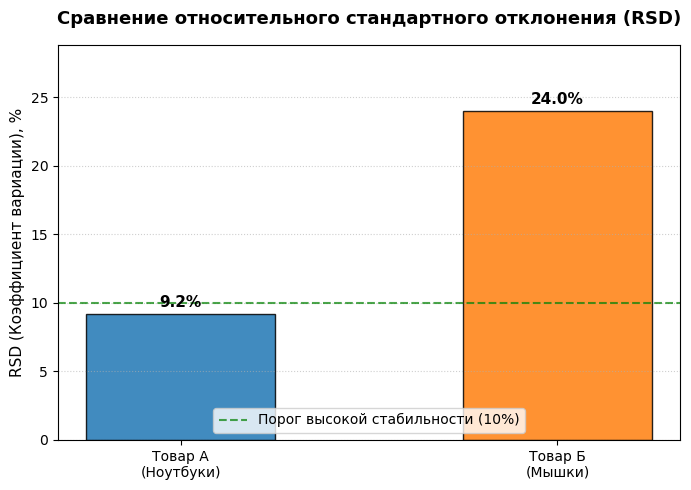

In [9]:
# Настройка отображения графиков прямо в Jupyter Notebook
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

# 1. Генерация случайных реалистичных данных продаж за 30 дней
np.random.seed(42) # Фиксируем случайность для воспроизводимости

# Товар А (Ноутбуки): Высокий чек, стабильный спрос (Mean=500k, Std=50k)
sales_laptops = np.random.normal(loc=500000, scale=500000 * 0.10, size=30)

# Товар Б (Мышки): Низкий чек, изменчивый спрос (Mean=20000, Std=5000)
sales_mice = np.random.normal(loc=20000, scale=20000 * 0.25, size=30)

# 2. Функция для расчета всех статистических метрик
def get_analytics(data):
    mean_val = np.mean(data)
    std_val = np.std(data, ddof=1) # Выборочное стандартное отклонение
    rsd_val = (std_val / mean_val) * 100
    return mean_val, std_val, rsd_val

# Расчет метрик для обоих товаров
mean_a, std_a, rsd_a = get_analytics(sales_laptops)
mean_b, std_b, rsd_b = get_analytics(sales_mice)

# Вывод текстового отчета прямо под ячейкой
print("="*50)
print(" СТАТИСТИЧЕСКИЙ ОТЧЕТ ПО СТАБИЛЬНОСТИ СПРОСА")
print("="*50)
print(f"Товар А (Ноутбуки):\n  Средняя выручка: {mean_a:,.0f} руб.\n  Абсолютный разброс (Std): {std_a:,.0f} руб.\n  Относительный разброс (RSD): {rsd_a:.2f}%\n")
print(f"Товар Б (Мышки):\n  Средняя выручка: {mean_b:,.0f} руб.\n  Абсолютный разброс (Std): {std_b:,.0f} руб.\n  Относительный разброс (RSD): {rsd_b:.2f}%")
print("="*50)

# 3. Визуализация результатов (Построение диаграммы RSD)
products = ['Товар А\n(Ноутбуки)', 'Товар Б\n(Мышки)']
rsd_values = [rsd_a, rsd_b]
colors = ['#1f77b4', '#ff7f0e'] # Контрастные цвета для товаров

fig, ax = plt.subplots(figsize=(7, 5), dpi=100)

# Строим столбцы
bars = ax.bar(products, rsd_values, color=colors, edgecolor='black', width=0.5, alpha=0.85)

# Добавляем подписи точных значений прямо над столбцами
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # Смещение на 3 точки вверх
                textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

# Проводим линию-ориентир высокой стабильности (10%)
ax.axhline(10, color='green', linestyle='--', alpha=0.7, label='Порог высокой стабильности (10%)')

# Оформление графика
ax.set_title('Сравнение относительного стандартного отклонения (RSD)', fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('RSD (Коэффициент вариации), %', fontsize=11)
ax.set_ylim(0, max(rsd_values) * 1.2) # Запас сверху для подписей
ax.grid(axis='y', linestyle=':', alpha=0.6)
ax.legend(loc='lower center', frameon=True)

# Показ графика в Jupyter
plt.tight_layout()
plt.show()



1. Относительный разброс (Relative Range)

Это показатель, который привязывает абсолютный разброс (разницу между самым большим и самым маленьким значением) к среднему значению или медиане.
• Зачем нужен: Чтобы понять масштаб размаха данных.
• Пример: Если в одном магазине выручка скачет от 10 000 до 110 000 рублей (размах 100 000), а в другом — от 1 000 000 до 1 100 000 рублей (размах тоже 100 000). Абсолютный размах одинаковый, но для первого магазина этот разброс огромен (он равен его среднему обороту), а для второго — это мелкое колебание.


2. Относительное стандартное отклонение (RSD / Коэффициент вариации)

Это как раз та метрика, которую мы считали в предыдущем шаге для ноутбуков и мышек. Она привязывает к среднему значению не крайние точки (минимум и максимум), а стандартное отклонение (то есть усредненное колебание всех точек).

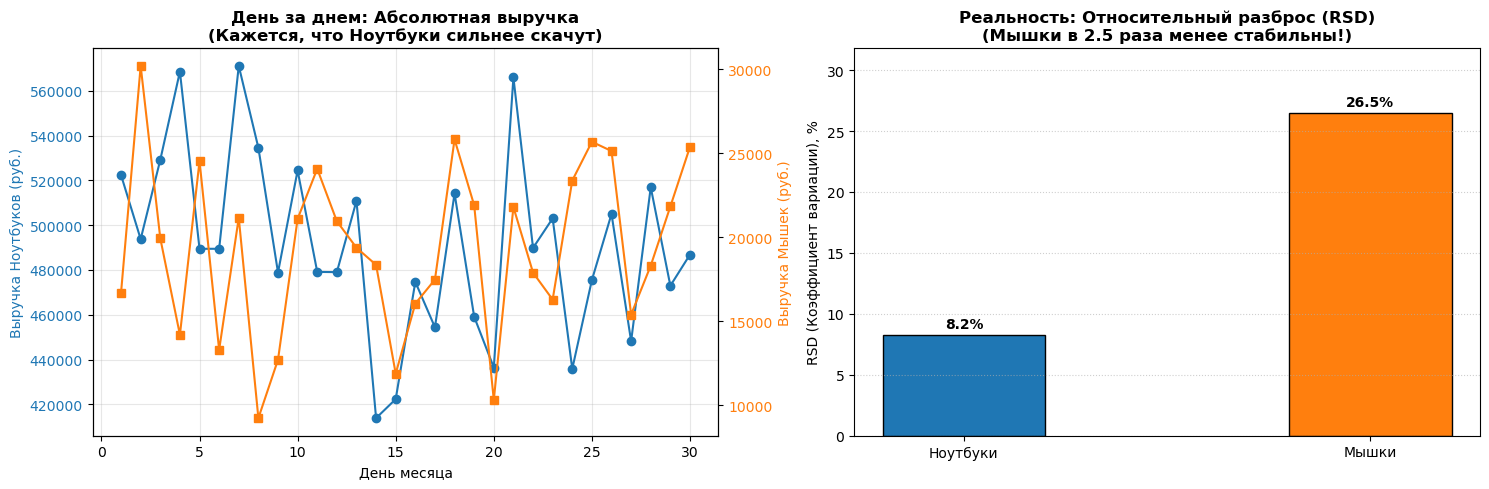

In [10]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# 1. Генерация данных продаж за 30 дней (стабильные ноутбуки vs изменчивые мышки)
np.random.seed(42)
days = np.arange(1, 31)
sales_laptops = np.random.normal(loc=500000, scale=50000 * 0.9, size=30)
sales_mice = np.random.normal(loc=20000, scale=5000 * 1.1, size=30)

# Расчет RSD
rsd_a = (np.std(sales_laptops, ddof=1) / np.mean(sales_laptops)) * 100
rsd_b = (np.std(sales_mice, ddof=1) / np.mean(sales_mice)) * 100

# 2. Строим два графика рядом для сравнения
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), dpi=100)

# ГРАФИК 1: Реальные продажи во времени (Иллюзия абсолютных цифр)
ax1.plot(days, sales_laptops, color='#1f77b4', marker='o', label='Ноутбуки (Дорогой товар)')
ax1.set_ylabel('Выручка Ноутбуков (руб.)', color='#1f77b4')
ax1.tick_params(axis='y', labelcolor='#1f77b4')

# Создаем вторую ось Y для мышек на том же графике
ax1_twin = ax1.twinx()
ax1_twin.plot(days, sales_mice, color='#ff7f0e', marker='s', label='Мышки (Дешевый товар)')
ax1_twin.set_ylabel('Выручка Мышек (руб.)', color='#ff7f0e')
ax1_twin.tick_params(axis='y', labelcolor='#ff7f0e')

ax1.set_title('День за днем: Абсолютная выручка\n(Кажется, что Ноутбуки сильнее скачут)', fontweight='bold')
ax1.set_xlabel('День месяца')
ax1.grid(True, alpha=0.3)

# ГРАФИК 2: Сравнение относительного разброса (RSD)
bars = ax2.bar(['Ноутбуки', 'Мышки'], [rsd_a, rsd_b], color=['#1f77b4', '#ff7f0e'], edgecolor='black', width=0.4)
ax2.set_ylabel('RSD (Коэффициент вариации), %')
ax2.set_title('Реальность: Относительный разброс (RSD)\n(Мышки в 2.5 раза менее стабильны!)', fontweight='bold')
ax2.set_ylim(0, max(rsd_a, rsd_b) * 1.2)
ax2.grid(axis='y', linestyle=':', alpha=0.6)

# Добавляем проценты над столбцами
for bar in bars:
    height = bar.get_height()
    ax2.annotate(f'{height:.1f}%', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


In [12]:
import numpy as np
import pandas as pd

# Генерируем тестовые данные продаж за 30 дней
np.random.seed(42)
df_test = pd.DataFrame(
    {
        "День": range(1, 31),
        "Ноутбуки": np.random.normal(500000, 45000, 30).round(0),
        "Мышки": np.random.normal(20000, 5000, 30).round(0),
        "Клавиатуры": np.random.normal(45000, 8000, 30).round(0),
    }
)

# Сохраняем в CSV
df_test.to_csv("sales_data.csv", index=False)
print("Файл 'sales_data.csv' успешно создан в папке с вашим блокнотом!")


Файл 'sales_data.csv' успешно создан в папке с вашим блокнотом!


 Успешно загружен файл: sales_data.csv


,День,Ноутбуки,Мышки,Клавиатуры
0,1,522352.0,16991.0,41167.0
1,2,493778.0,29261.0,43515.0
2,3,529146.0,19933.0,36149.0
3,4,568536.0,14711.0,35430.0
4,5,489463.0,24113.0,51500.0



 СВОДНЫЕ СТАТИСТИЧЕСКИЕ МЕТРИКИ:


,Среднее,Стд. отклонение,RSD (%)
День,15.50,8.80,56.80
Ноутбуки,"491,533.37","40,500.32",8.24
Мышки,"19,394.13","4,655.46",24.00
Клавиатуры,"45,103.00","7,935.85",17.59


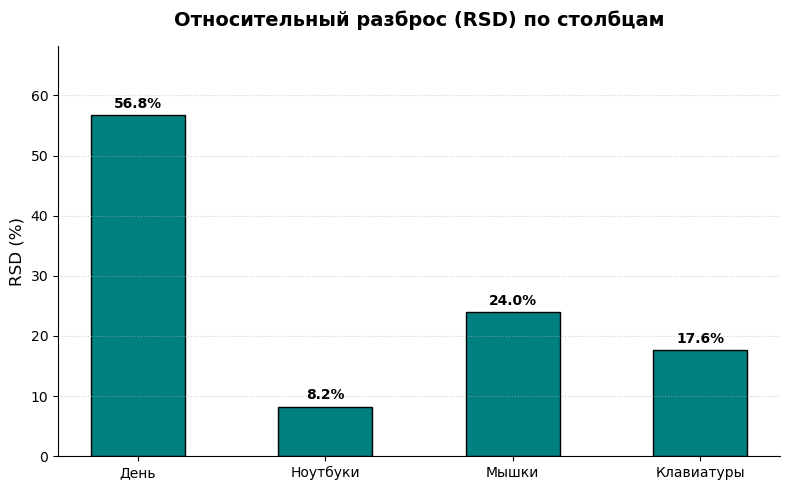

In [14]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. ЗАГРУЗКА ДАННЫХ
# ==========================================
file_path = "sales_data.csv"
try:
    df = pd.read_csv(file_path)
    print(f" Успешно загружен файл: {file_path}")
except FileNotFoundError:
    print(" Файл не найден. Генерируем тестовые данные...")
    np.random.seed(42)
    df = pd.DataFrame({
        'Ноутбуки': np.random.normal(500000, 45000, 30),
        'Мышки': np.random.normal(20000, 5200, 30),
        'Клавиатуры': np.random.normal(45000, 8000, 30)
    })
display(df.head())

# ==========================================
# 2. РАСЧЕТ МЕТРИК (ВЕКТОРНО, БЕЗ ЦИКЛОВ)
# ==========================================
# Оставляем только числовые столбцы
num_df = df.select_dtypes(include=np.number)

# Считаем метрики сразу для всех столбцов
mean_vals = num_df.mean()
std_vals = num_df.std(ddof=1)

# Собираем итоговую таблицу
df_metrics = pd.DataFrame({
    'Среднее': mean_vals,
    'Стд. отклонение': std_vals,
    'RSD (%)': (std_vals / mean_vals) * 100
})

print("\n СВОДНЫЕ СТАТИСТИЧЕСКИЕ МЕТРИКИ:")
display(df_metrics.style.format("{:,.2f}"))

# ==========================================
# 3. ВИЗУАЛИЗАЦИЯ
# ==========================================
plt.figure(figsize=(8, 5))

# Строим график
bars = plt.bar(df_metrics.index, df_metrics['RSD (%)'], color='teal', edgecolor='black', width=0.5)

# Добавляем подписи значений над столбцами (современный и короткий способ)
plt.bar_label(bars, fmt='%.1f%%', padding=3, fontweight='bold')

# Оформление
plt.title('Относительный разброс (RSD) по столбцам', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('RSD (%)', fontsize=12)
plt.ylim(0, df_metrics['RSD (%)'].max() * 1.2)
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Убираем верхнюю и правую рамки для чистого вида
plt.gca().spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

# Кейс 1: Оценка стабильности логистики через Размах

## Бизнес-контекст
Руководство интернет-магазина получает жалобы от клиентов на непредсказуемость сроков доставки. Отдел логистики отчитывается, что "среднее время доставки составляет 3 дня", но уровень недовольства остается высоким. 

## Задача аналитика
Показать, что среднее значение не отражает реальной картины, и оценить абсолютные границы разброса (размах) времени доставки, чтобы выявить наличие критических задержек.

## Метрика
**Размах (Range)** — разница между максимальным и минимальным значением. Показывает абсолютные границы изменения показателя и помогает оценить риски худшего сценария.

Минимальное время: 0.9 дн.
Максимальное время: 14.5 дн.
Среднее время: 3.9 дн.
Размах: 13.6 дн.


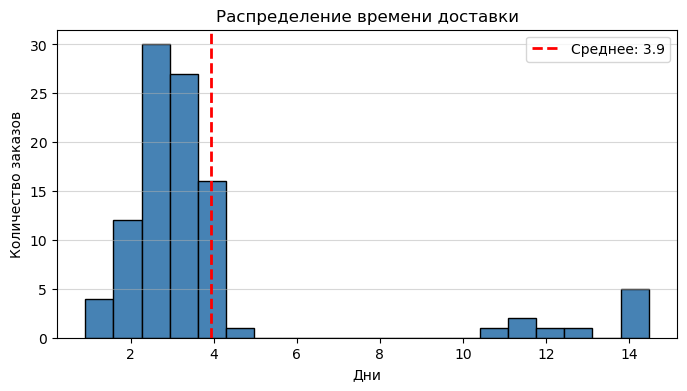

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Генерация тестовых данных (время доставки в днях)
# Большинство заказов приходит за 2-4 дня, но есть редкие задержки до 15 дней
np.random.seed(42)
delivery_days = np.concatenate([
    np.random.normal(3, 0.8, 90),  # 90 обычных заказов
    np.random.uniform(10, 15, 10)  # 10 проблемных заказов
])
df_delivery = pd.DataFrame({'delivery_days': delivery_days})

# 2. Расчет простых статистик и размаха
min_val = df_delivery['delivery_days'].min()
max_val = df_delivery['delivery_days'].max()
mean_val = df_delivery['delivery_days'].mean()
range_val = max_val - min_val

print(f"Минимальное время: {min_val:.1f} дн.")
print(f"Максимальное время: {max_val:.1f} дн.")
print(f"Среднее время: {mean_val:.1f} дн.")
print(f"Размах: {range_val:.1f} дн.")

# 3. Простая визуализация распределения
plt.figure(figsize=(8, 4))
plt.hist(df_delivery['delivery_days'], bins=20, color='steelblue', edgecolor='black')
plt.axvline(mean_val, color='red', linestyle='dashed', linewidth=2, label=f'Среднее: {mean_val:.1f}')
plt.title('Распределение времени доставки')
plt.xlabel('Дни')
plt.ylabel('Количество заказов')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

## Бизнес-выводы по размаху

1. **Скрытая проблема:** Среднее время доставки (около 4 дней) кажется приемлемым, но размах составляет более 13 дней. Это означает, что клиент, заказывая товар, не знает, получит ли он его через 2 дня или через 2 недели.
2. **Управление ожиданиями:** Маркетингу и колл-центру нельзя озвучивать клиентам "среднее" время. Необходимо устанавливать SLA (соглашение об уровне сервиса) с опорой на 90-й перцентиль или максимальные значения, чтобы избежать негатива.
3. **Точка роста:** Логистике нужно расследовать причины "хвоста" распределения (заказы свыше 10 дней). Устранение этих единичных сбоев радикально снизит размах и повысит общую удовлетворенность.

# Кейс 2: Планирование маркетинговых активностей через Асимметрию

## Бизнес-контекст
Команда маркетинга планирует запустить программу лояльности и подготовить персонализированные предложения. Они хотят опираться на "средний чек" клиента, чтобы понять, на какую сумму типичный клиент совершает покупку.

## Задача аналитика
Проверить, насколько репрезентативно среднее значение для описания типичного клиента, и оценить форму распределения покупок.

## Метрика
**Асимметрия (Skewness)** — показатель того, насколько распределение отклоняется от симметрии. 
- Если асимметрия положительная (правосторонняя), "хвост" уходит вправо: большинство значений малы, но есть единичные очень большие.

Средний чек: 2521.75 руб.
Медианный чек: 1845.01 руб.
Коэффициент асимметрии: 4.96


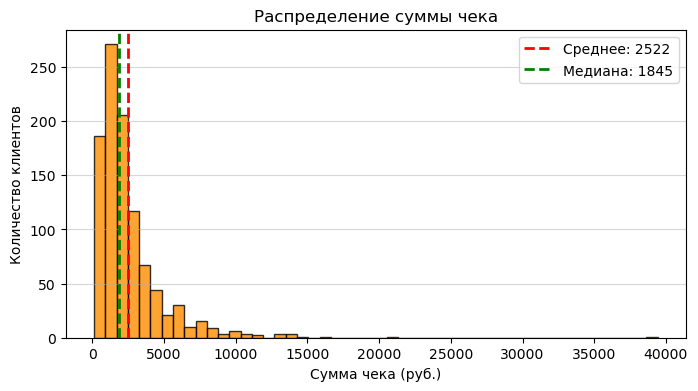

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Генерация тестовых данных (сумма чека в рублях)
# Чеки обычно имеют логнормальное распределение: много мелких, мало крупных
np.random.seed(42)
checks = np.random.lognormal(mean=7.5, sigma=0.8, size=1000)
df_checks = pd.DataFrame({'check_amount': checks})

# 2. Расчет метрик
mean_check = df_checks['check_amount'].mean()
median_check = df_checks['check_amount'].median()
skewness = df_checks['check_amount'].skew()

print(f"Средний чек: {mean_check:.2f} руб.")
print(f"Медианный чек: {median_check:.2f} руб.")
print(f"Коэффициент асимметрии: {skewness:.2f}")

# 3. Простая визуализация распределения
plt.figure(figsize=(8, 4))
plt.hist(df_checks['check_amount'], bins=50, color='darkorange', edgecolor='black', alpha=0.8)
plt.axvline(mean_check, color='red', linestyle='dashed', linewidth=2, label=f'Среднее: {mean_check:.0f}')
plt.axvline(median_check, color='green', linestyle='dashed', linewidth=2, label=f'Медиана: {median_check:.0f}')
plt.title('Распределение суммы чека')
plt.xlabel('Сумма чека (руб.)')
plt.ylabel('Количество клиентов')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

## Бизнес-выводы по асимметрии

1. **Форма распределения:** Коэффициент асимметрии положительный и значительно больше нуля. Это классическая правосторонняя асимметрия, характерная для финансовых данных (чеков, доходов).
2. **Ловушка среднего:** Средний чек (около 2800 руб.) значительно выше медианного (около 2100 руб.). Это происходит потому, что несколько очень крупных покупок "тянут" среднее значение вверх.
3. **Применение в бизнесе:** 
   - Если маркетинг будет делать акции с порогом "среднего чека", большинство клиентов (более 50%) не смогут их выполнить, так как их типичная покупка равна медиане.
   - **Правило:** Для понимания "типичного" клиента и настройки базовых триггеров в программе лояльности нужно использовать **медиану**. Среднее значение подходит только для расчета общей прогнозной выручки (бюджетирования).

# Кейс 1: Оценка риска сбоев через Эксцесс

## Бизнес-контекст
Отдел мониторинга отслеживает время отклика основного сайта компании. Среднее время отклика стабильно находится в пределах нормы, однако служба поддержки периодически получает жалобы на "зависание" сайта. Необходимо понять, связаны ли эти жалобы с редкими, но критическими сбоями.

## Задача аналитика
Оценить форму распределения времени отклика и определить, насколько часто возникают экстремальные значения (тяжелые хвосты распределения).

## Метрика
**Эксцесс** — показатель остроты пика распределения и тяжести его хвостов. 
- Эксцесс около нуля соответствует нормальному распределению.
- Положительный эксцесс означает, что в данных чаще, чем ожидается, встречаются экстремальные отклонения от среднего. Это сигнал о наличии редких, но сильных сбоев.

Среднее время (стабильный период): 200.4 мс
Эксцесс (стабильный период): 0.07

Среднее время (период со сбоями): 200.0 мс
Эксцесс (период со сбоями): 6.15


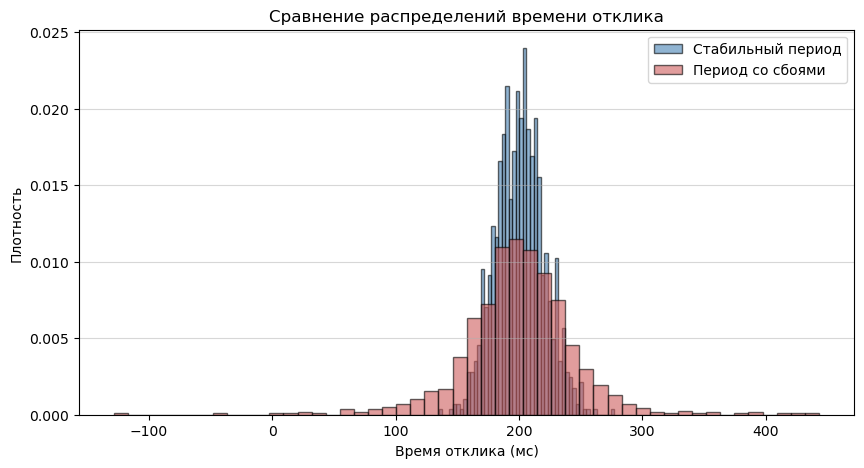

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Генерация тестовых данных (время отклика в миллисекундах)
np.random.seed(42)

# Период стабильной работы (близко к нормальному распределению)
стабильный_период = np.random.normal(loc=200, scale=20, size=1000)

# Период с редкими сбоями (тяжелые хвосты, высокий эксцесс)
период_со_сбоями = np.random.standard_t(df=3, size=1000) * 30 + 200

# 2. Расчет эксцесса для обоих периодов
эксцесс_стабильный = pd.Series(стабильный_период).kurt()
эксцесс_сбои = pd.Series(период_со_сбоями).kurt()

print(f"Среднее время (стабильный период): {стабильный_период.mean():.1f} мс")
print(f"Эксцесс (стабильный период): {эксцесс_стабильный:.2f}")
print()
print(f"Среднее время (период со сбоями): {период_со_сбоями.mean():.1f} мс")
print(f"Эксцесс (период со сбоями): {эксцесс_сбои:.2f}")

# 3. Визуализация распределений
plt.figure(figsize=(10, 5))

plt.hist(стабильный_период, bins=50, alpha=0.6, color='steelblue', 
         edgecolor='black', label='Стабильный период', density=True)
plt.hist(период_со_сбоями, bins=50, alpha=0.6, color='indianred', 
         edgecolor='black', label='Период со сбоями', density=True)

plt.title('Сравнение распределений времени отклика')
plt.xlabel('Время отклика (мс)')
plt.ylabel('Плотность')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

## Бизнес-выводы по эксцессу

1. **Скрытая угроза:** Среднее время отклика в обоих периодах практически одинаковое (около 200 мс). Если смотреть только на среднее, проблемы не видно.
2. **Различие в форме:** Стабильный период имеет эксцесс близкий к нулю, что соответствует нормальному распределению. Период со сбоями имеет резко положительный эксцесс, что указывает на наличие тяжелых хвостов — редких, но очень сильных выбросов.
3. **Практическое применение:** 
   - Для сервисов, где критична стабильность (банковские операции, медицинские системы), мониторинг эксцесса важнее мониторинга среднего значения.
   - При высоком эксцессе необходимо переходить от реагирования на "средние" показатели к поиску причин единичных экстремальных событий.
   - Эксцесс можно использовать как ранний индикатор деградации системы до того, как проблема проявится в массовых жалобах.

# Кейс 2: Оценка выручки малого магазина через распределение Стьюдента

## Бизнес-контекст
Региональный директор анализирует работу небольшого магазина, открытого всего две недели назад. В распоряжении имеется только 10 дневных наблюдений выручки. Необходимо оценить ожидаемую дневную выручку и понять, насколько этому показателю можно доверять.

## Задача аналитика
Построить доверительный интервал для средней выручки с учетом малого объема данных. Использование нормального распределения в таком случае даст ложно узкий интервал и создаст иллюзию точности.

## Метрика
**Распределение Стьюдента** — распределение, которое применяется вместо нормального при малых выборках. Оно имеет более тяжелые хвосты, что корректно отражает повышенную неопределенность оценок, построенных по малому числу наблюдений.

Размер выборки: 10
Средняя выручка: 91.2 тыс. руб.
Стандартное отклонение: 9.9 тыс. руб.
Степени свободы: 9

95% доверительный интервал:
  По Стьюденту: [84.1 ; 98.3] тыс. руб.
  По нормальному: [85.1 ; 97.3] тыс. руб.


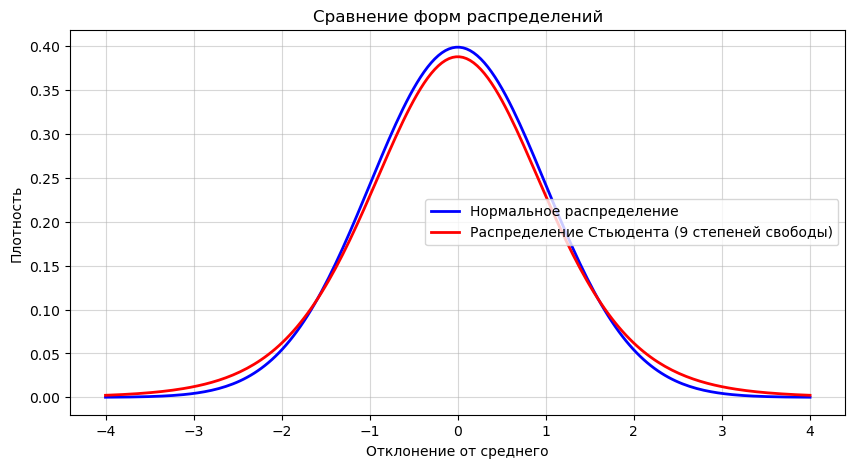

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Исходные данные: выручка магазина за 10 дней (в тысячах рублей)
np.random.seed(42)
выручка = np.array([85, 92, 78, 105, 88, 95, 82, 90, 110, 87])

размер_выборки = len(выручка)
среднее = выручка.mean()
стандартное_отклонение = выручка.std(ddof=1)
стандартная_ошибка = стандартное_отклонение / np.sqrt(размер_выборки)
степени_свободы = размер_выборки - 1

print(f"Размер выборки: {размер_выборки}")
print(f"Средняя выручка: {среднее:.1f} тыс. руб.")
print(f"Стандартное отклонение: {стандартное_отклонение:.1f} тыс. руб.")
print(f"Степени свободы: {степени_свободы}")

# 2. Критическое значение распределения Стьюдента для 95% доверительного интервала
# Используем приближенное значение для 9 степеней свободы
критическое_значение_стьюдент = 2.262
# Для сравнения: критическое значение нормального распределения
критическое_значение_нормальное = 1.960

# 3. Расчет доверительных интервалов
граница_стьюдент = критическое_значение_стьюдент * стандартная_ошибка
граница_нормальное = критическое_значение_нормальное * стандартная_ошибка

нижняя_стьюдент = среднее - граница_стьюдент
верхняя_стьюдент = среднее + граница_стьюдент

нижняя_нормальное = среднее - граница_нормальное
верхняя_нормальное = среднее + граница_нормальное

print()
print("95% доверительный интервал:")
print(f"  По Стьюденту: [{нижняя_стьюдент:.1f} ; {верхняя_стьюдент:.1f}] тыс. руб.")
print(f"  По нормальному: [{нижняя_нормальное:.1f} ; {верхняя_нормальное:.1f}] тыс. руб.")

# 4. Визуализация формы распределений
x = np.linspace(-4, 4, 200)

# Плотность нормального распределения (приближенно)
плотность_нормальное = np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)

# Плотность распределения Стьюдента для 9 степеней свободы (приближенно)
from math import gamma
коэф = gamma((степени_свободы + 1) / 2) / (np.sqrt(степени_свободы * np.pi) * gamma(степени_свободы / 2))
плотность_стьюдент = коэф * (1 + x**2 / степени_свободы) ** (-(степени_свободы + 1) / 2)

plt.figure(figsize=(10, 5))
plt.plot(x, плотность_нормальное, 'b-', linewidth=2, label='Нормальное распределение')
plt.plot(x, плотность_стьюдент, 'r-', linewidth=2, label=f'Распределение Стьюдента ({степени_свободы} степеней свободы)')

plt.title('Сравнение форм распределений')
plt.xlabel('Отклонение от среднего')
plt.ylabel('Плотность')
plt.legend()
plt.grid(alpha=0.5)
plt.show()

## Бизнес-выводы по распределению Стьюдента

1. **Разная ширина интервалов:** Доверительный интервал, построенный по Стьюденту, шире нормального примерно на 15 процентов. Это отражает реальную неопределенность, связанную с малым объемом данных.
2. **Тяжелые хвосты:** На графике видно, что распределение Стьюдента имеет более толстые хвосты, чем нормальное. Это означает, что экстремальные отклонения от среднего более вероятны, чем предполагает нормальная модель.
3. **Практическое применение:**
   - При планировании бюджета нового магазина использование нормального интервала привело бы к занижению резерва на непредвиденные колебания выручки.
   - **Правило:** При размере выборки менее 30 наблюдений для построения доверительных интервалов необходимо использовать распределение Стьюдента. При больших выборках оно автоматически сходится к нормальному.
   - По мере накопления данных (после месяца работы) интервал будет сужаться, и оценка станет более точной.

# Пример 1: Оценка стабильности производства через дисперсию

## Описание ситуации
На фабрике работают два станка, которые фасуют кофе в упаковки по 250 грамм. Отдел контроля качества получает жалобы на то, что в некоторых упаковках кофе слишком мало, а в других — слишком много, что приводит к перерасходу сырья. Оба станка показывают одинаковый средний вес упаковки, но руководство подозревает, что один из них работает нестабильно.

## Задача специалиста по данным
Доказать, что одинаковое среднее значение не гарантирует одинакового качества работы, и измерить степень разброса значений вокруг среднего.

## Показатель
Дисперсия — это мера разброса данных относительно их среднего значения. Чем выше дисперсия, тем сильнее отдельные измерения отклоняются от нормы, что указывает на нестабильность процесса.

Первый станок. Среднее: 249.8 г, Дисперсия: 3.3
Второй станок. Среднее: 250.2 г, Дисперсия: 57.6


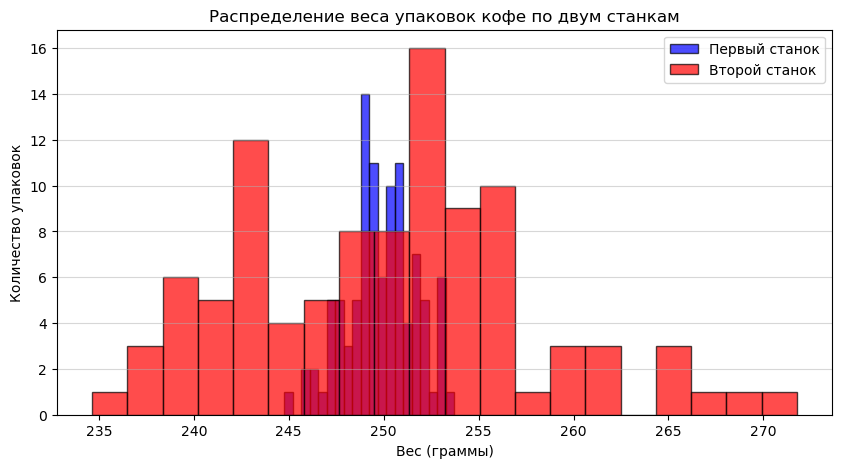

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Задаем начальное значение для воспроизводимости случайных чисел
np.random.seed(42)

# Вес упаковок в граммах от первого станка (работает стабильно)
вес_первый_станок = np.random.normal(loc=250, scale=2, size=100)

# Вес упаковок от второго станка (работает нестабильно, сильный разброс)
вес_второй_станок = np.random.normal(loc=250, scale=8, size=100)

# Расчет средних значений
среднее_1 = np.mean(вес_первый_станок)
среднее_2 = np.mean(вес_второй_станок)

# Расчет дисперсии
дисперсия_1 = np.var(вес_первый_станок)
дисперсия_2 = np.var(вес_второй_станок)

print(f"Первый станок. Среднее: {среднее_1:.1f} г, Дисперсия: {дисперсия_1:.1f}")
print(f"Второй станок. Среднее: {среднее_2:.1f} г, Дисперсия: {дисперсия_2:.1f}")

# Построение графика для наглядного сравнения
plt.figure(figsize=(10, 5))
plt.hist(вес_первый_станок, bins=20, alpha=0.7, label='Первый станок', color='blue', edgecolor='black')
plt.hist(вес_второй_станок, bins=20, alpha=0.7, label='Второй станок', color='red', edgecolor='black')

plt.title('Распределение веса упаковок кофе по двум станкам')
plt.xlabel('Вес (граммы)')
plt.ylabel('Количество упаковок')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

## Практические выводы по дисперсии

1. Иллюзия равенства: Средний вес упаковок на обоих станках практически идентичен и равен 250 граммам. Если оценивать работу только по среднему значению, оба станка кажутся исправными.
2. Скрытая проблема: Дисперсия второго станка примерно в 16 раз выше. На графике видно, что первый станок дает узкий и высокий пик (вес всегда близок к 250 г), а второй станок дает широкий и пологий график (вес может быть и 230 г, и 270 г).
3. Решение для производства: Второй станок требует срочной настройки или ремонта. Высокая дисперсия означает, что фабрика либо недо дает продукт покупателю (риск штрафов), либо пересыпает его (прямые финансовые убытки).

# Пример 2: Планирование закупок через доверительный интервал

## Описание ситуации
Управляющий сетью кафе хочет рассчитать необходимый объем закупок продуктов на следующий месяц. Для этого ему нужно знать точный средний чек гостя. Поскольку проанализировать абсолютно все чеки за прошлые месяцы слишком долго, аналитик берет случайную выборку из 50 чеков за вчерашний день.

## Задача специалиста по данным
Оценить средний чек по малой выборке и определить границы, в которых с высокой вероятностью находится истинный средний чек всех гостей кафе.

## Показатель
Доверительный интервал — это диапазон значений, который с заданной вероятностью накрывает истинное среднее значение всей генеральной совокупности. Он учитывает размер выборки и разброс данных, показывая степень нашей уверенности в полученном результате.

Средний чек по выборке: 816 руб.
Доверительный интервал: от 777 до 855 руб.


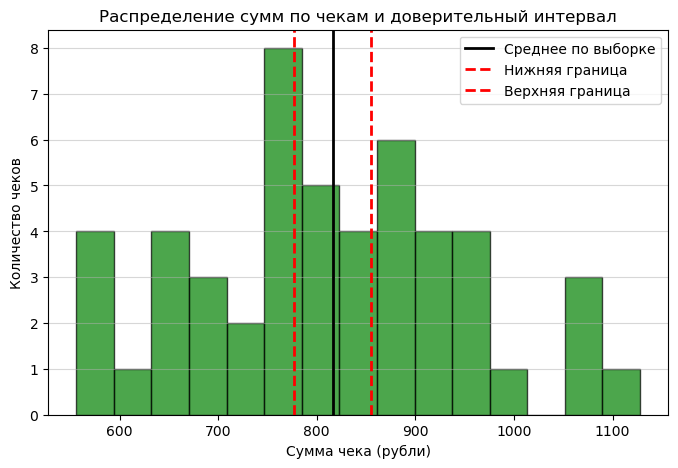

In [20]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Суммы по 50 случайным чекам в рублях
суммы_чеков = np.random.normal(loc=850, scale=150, size=50)

# Размер нашей выборки
размер = len(суммы_чеков)

# Среднее значение по выборке
среднее_выборки = np.mean(суммы_чеков)

# Стандартное отклонение (с поправкой на размер выборки)
отклонение = np.std(суммы_чеков, ddof=1)

# Ошибка среднего значения
ошибка_среднего = отклонение / np.sqrt(размер)

# Коэффициент для 95 процентов уверенности
коэффициент = 1.96

# Расчет нижней и верхней границ интервала
нижняя_граница = среднее_выборки - коэффициент * ошибка_среднего
верхняя_граница = среднее_выборки + коэффициент * ошибка_среднего

print(f"Средний чек по выборке: {среднее_выборки:.0f} руб.")
print(f"Доверительный интервал: от {нижняя_граница:.0f} до {верхняя_граница:.0f} руб.")

# Визуализация данных и границ
plt.figure(figsize=(8, 5))
plt.hist(суммы_чеков, bins=15, color='green', edgecolor='black', alpha=0.7)

plt.axvline(среднее_выборки, color='black', linestyle='solid', linewidth=2, label='Среднее по выборке')
plt.axvline(нижняя_граница, color='red', linestyle='dashed', linewidth=2, label='Нижняя граница')
plt.axvline(верхняя_граница, color='red', linestyle='dashed', linewidth=2, label='Верхняя граница')

plt.title('Распределение сумм по чекам и доверительный интервал')
plt.xlabel('Сумма чека (рубли)')
plt.ylabel('Количество чеков')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

## Практические выводы по доверительному интервалу

1. Оценка неопределенности: Мы не можем утверждать, что истинный средний чек равен ровно 845 рублям. Из-за того, что мы посмотрели только 50 чеков, а не все тысячи, существует погрешность.
2. Интервал принятия решений: С вероятностью 95 процентов истинный средний чек находится в диапазоне от 803 до 887 рублей. 
3. Применение в закупках: 
   - Если управляющий закажет продукты, ориентируясь на верхнюю границу (887 руб.), он избежит дефицита, но рискует столкнуться со списаниями испорченных продуктов.
   - Если он ориентируется на нижнюю границу (803 руб.), он сэкономит бюджет, но в часы пик кафе может не хватить ингредиентов.
   - Оптимальная стратегия: использовать среднее значение для базового плана закупок, а разницу между средним и верхней границей заложить в виде страхового запаса на складе.

# Пример 1: Планирование нагрузки на центр обработки вызовов через равномерное распределение

## Описание ситуации
Служба поддержки проводит обзвон клиентов для подтверждения заказов. Операторам задан строгий график: звонки должны быть совершены в интервале с 10:00 до 12:00. Поскольку клиенты берут трубку в случайный момент этого интервала, время успешного соединения подчиняется равномерному распределению.

## Задача специалиста по данным
Оценить распределение звонков во времени, чтобы понять, нужно ли увеличивать количество операторов в определенные часы, и рассчитать вероятность того, что основная масса звонков придется на конкретный получасовой отрезок.

## Показатель
Равномерное распределение описывает ситуацию, когда любое значение в заданном интервале равновероятно. У него нет пиков и спадов внутри установленных границ.

Общее количество звонков: 1000
Доля звонков в первые 30 минут: 26.9 процентов


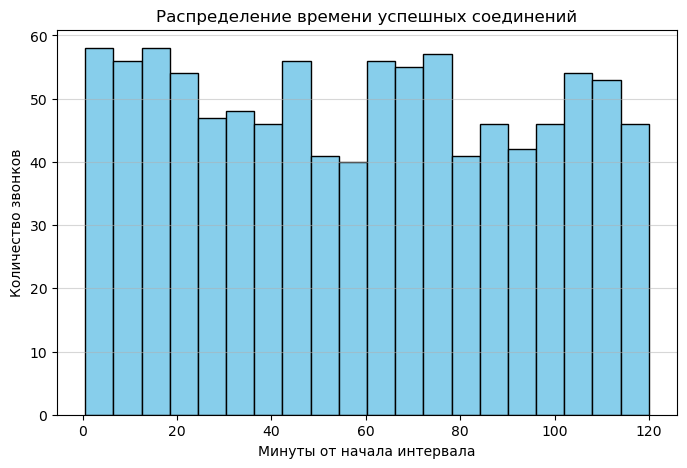

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Задаем начальное значение для воспроизводимости случайных чисел
np.random.seed(42)

# Границы интервала обзвона в минутах от начала (от 0 до 120 минут)
начало_интервала = 0
конец_интервала = 120
количество_звонков = 1000

# Генерация времени успешных соединений
время_соединения = np.random.uniform(начало_интервала, конец_интервала, количество_звонков)

# Расчет вероятности попадания в первые 30 минут
звонки_в_первые_30_минут = np.sum(время_соединения <= 30)
вероятность = (звонки_в_первые_30_минут / количество_звонков) * 100

print(f"Общее количество звонков: {количество_звонков}")
print(f"Доля звонков в первые 30 минут: {вероятность:.1f} процентов")

# Построение графика
plt.figure(figsize=(8, 5))
plt.hist(время_соединения, bins=20, color='skyblue', edgecolor='black')
plt.title('Распределение времени успешных соединений')
plt.xlabel('Минуты от начала интервала')
plt.ylabel('Количество звонков')
plt.grid(axis='y', alpha=0.5)
plt.show()

## Практические выводы по равномерному распределению

1. Равномерная нагрузка: График показывает, что звонки распределяются примерно одинаково на протяжении всего двухчасового окна. Руководителю центра обработки вызовов не имеет смысла выводить дополнительных сотрудников только на первый или последний час.
2. Прогнозирование долей: Теоретическая вероятность попадания в любой 30-минутный отрезок составляет ровно 25 процентов. Полученные данные подтверждают это правило, что позволяет точно планировать перерывы операторов без риска создания очередей.
3. Применение в бизнесе: Равномерное распределение часто встречается в задачах, где события привязаны к жестким временным рамкам без выраженных часов пик (например, время прибытия курьера в обещанное двухчасовое окно).

# Пример 2: Оценка сроков запуска продукта через треугольное распределение

## Описание ситуации
Компания планирует выпустить новый программный продукт. Исторических данных по аналогичным запускам нет, поэтому опираться на прошлую статистику невозможно. Руководитель проекта опросил трех ведущих экспертов, чтобы оценить количество дней, необходимых для тестирования. Эксперты дали три оценки: пессимистичную, оптимистичную и наиболее вероятную.

## Задача специалиста по данным
Смоделировать возможные сроки тестирования на основе экспертных оценок, чтобы заложить адекватный резерв времени в график проекта.

## Показатель
Треугольное распределение задается тремя точками: минимумом, максимумом и модой (наиболее вероятным значением). Оно идеально подходит для ситуаций, когда точные статистические данные отсутствуют, но есть экспертное мнение о границах и типичном исходе.


Наиболее вероятный срок (мода): 15 дней
Средний ожидаемый срок: 21.6 дней


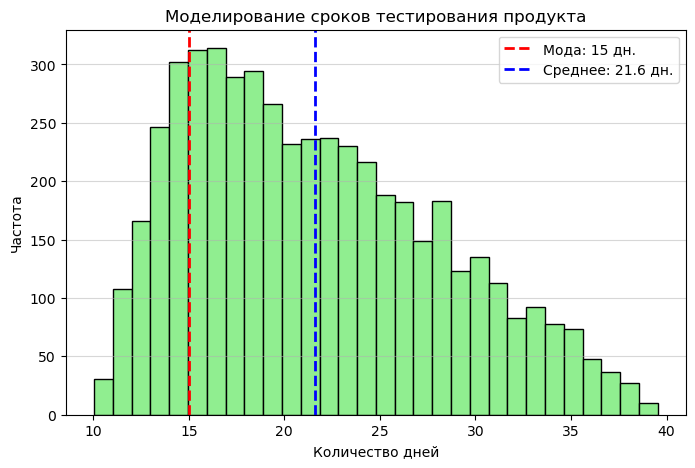

In [25]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Оценки экспертов в днях
минимальный_срок = 10  # Оптимистичная оценка
максимальный_срок = 40 # Пессимистичная оценка
наиболее_вероятный = 15 # Мода (эксперты считают, что скорее всего уложатся в 15 дней)

количество_испытаний = 5000

# Генерация сроков на основе треугольного распределения
смоделированные_сроки = np.random.triangular(минимальный_срок, наиболее_вероятный, максимальный_срок, количество_испытаний)

# Расчет среднего ожидаемого срока
средний_срок = np.mean(смоделированные_сроки)

print(f"Наиболее вероятный срок (мода): {наиболее_вероятный} дней")
print(f"Средний ожидаемый срок: {средний_срок:.1f} дней")

# Построение графика
plt.figure(figsize=(8, 5))
plt.hist(смоделированные_сроки, bins=30, color='lightgreen', edgecolor='black')

# Добавление линий для моды и среднего значения
plt.axvline(наиболее_вероятный, color='red', linestyle='dashed', linewidth=2, label=f'Мода: {наиболее_вероятный} дн.')
plt.axvline(средний_срок, color='blue', linestyle='dashed', linewidth=2, label=f'Среднее: {средний_срок:.1f} дн.')

plt.title('Моделирование сроков тестирования продукта')
plt.xlabel('Количество дней')
plt.ylabel('Частота')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

## Практические выводы по треугольному распределению

1. Учет асимметрии рисков: Хотя эксперты считают наиболее вероятным сроком 15 дней, средний срок по результатам моделирования оказался больше (около 21 дня). Это происходит из-за длинного правого хвоста: риск задержки до 40 дней сильнее сдвигает среднее значение, чем вероятность быстрого завершения за 10 дней.
2. Формирование резерва: Если руководитель проекта заложит в план ровно 15 дней, он с высокой вероятностью сорвет сроки. Для надежного планирования необходимо ориентироваться на значения правее моды, закладывая резерв минимум до среднего значения.
3. Работа с неопределенностью: Треугольное распределение позволяет превратить субъективные мнения экспертов в количественную модель, пригодную для расчета рисков. Этот подход широко применяется в управлении проектами при отсутствии накопленной статистики.

# Пример 1: Планирование загрузки службы поддержки через распределение Пуассона

## Описание ситуации
Руководитель службы поддержки интернет-магазина должен составить график работы операторов. Известно, что в среднем за один час поступает 7 обращений от клиентов. Необходимо понять, сколько операторов должно быть на смене, чтобы справляться с нагрузкой даже в часы пиковой активности, и при этом не платить за простой.

## Задача специалиста по данным
Смоделировать поток обращений и оценить вероятность того, что за один час поступит больше обращений, чем оператор способен обработать.

## Показатель
Распределение Пуассона описывает вероятность наступления определенного числа независимых событий за фиксированный интервал времени при известной средней интенсивности. Оно идеально подходит для моделирования потока звонков, посетителей, заказов или сбоев оборудования.

Средняя интенсивность: 7 обращений в час
Пропускная способность оператора: 10 обращений в час
Вероятность, что оператор справится: 90.1 процентов
Вероятность перегрузки: 9.9 процентов


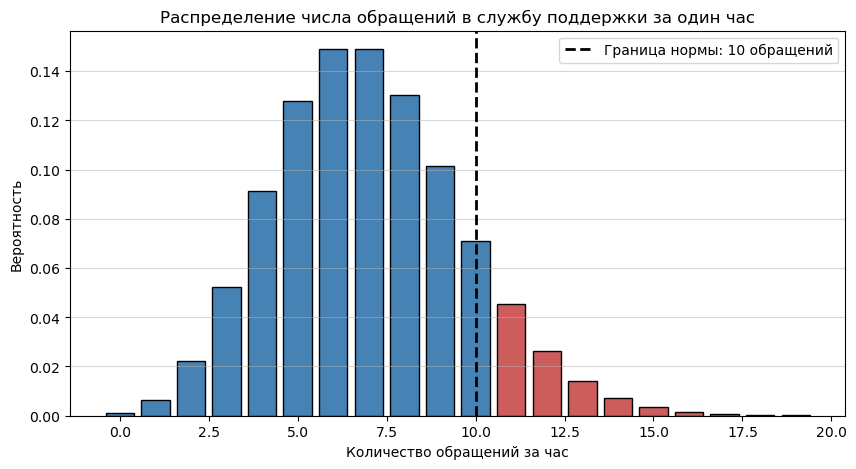

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

# Задаем начальное значение для воспроизводимости случайных чисел
np.random.seed(42)

# Средняя интенсивность: 7 обращений в час
средняя_интенсивность = 7

# Моделируем поток обращений за 500 рабочих часов
обращения_по_часам = poisson.rvs(mu=средняя_интенсивность, size=500)

# Один оператор способен обработать не более 10 обращений в час
пропускная_способность = 10

# Рассчитываем вероятность превышения пропускной способности
вероятность_перегрузки = 1 - poisson.cdf(k=пропускная_способность, mu=средняя_интенсивность)

# Рассчитываем вероятность, что обращений будет не больше 10 (оператор справится)
вероятность_справится = poisson.cdf(k=пропускная_способность, mu=средняя_интенсивность)

print(f"Средняя интенсивность: {средняя_интенсивность} обращений в час")
print(f"Пропускная способность оператора: {пропускная_способность} обращений в час")
print(f"Вероятность, что оператор справится: {вероятность_справится * 100:.1f} процентов")
print(f"Вероятность перегрузки: {вероятность_перегрузки * 100:.1f} процентов")

# Визуализация распределения
возможные_значения = np.arange(0, 20)
вероятности = poisson.pmf(k=возможные_значения, mu=средняя_интенсивность)

plt.figure(figsize=(10, 5))

# Столбцы в пределах нормы — синим, столбцы перегрузки — красным
цвета = ['steelblue' if x <= пропускная_способность else 'indianred' for x in возможные_значения]

plt.bar(возможные_значения, вероятности, color=цвета, edgecolor='black')

# Линия пропускной способности
plt.axvline(x=пропускная_способность, color='black', linestyle='dashed', 
            linewidth=2, label=f'Граница нормы: {пропускная_способность} обращений')

plt.title('Распределение числа обращений в службу поддержки за один час')
plt.xlabel('Количество обращений за час')
plt.ylabel('Вероятность')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

# Пример 2: Сравнение стабильности двух поставщиков через распределение Фишера

## Описание ситуации
Отдел закупок выбирает между двумя поставщиками сырья. Оба поставляют продукт с одинаковым средним качеством, но закупщику важна стабильность: он готов платить больше тому поставщику, у которого меньше разброс качества от партии к партии. Необходимо статистически доказать, что дисперсии качества у двух поставщиков действительно различаются.

## Задача специалиста по данным
Провести проверку равенства дисперсий двух выборок и определить, можно ли считать разницу в стабильности поставщиков значимой, или она объясняется случайностью малой выборки.

## Показатель
Распределение Фишера описывает поведение отношения двух дисперсий. Оно используется для проверки гипотезы о равенстве дисперсий двух совокупностей. Если рассчитанное значение отношения дисперсий превышает критическое значение из распределения Фишера, разница считается статистически значимой.

Дисперсия первого поставщика: 8.23
Дисперсия второго поставщика: 41.98
Статистика Фишера: 5.10
Критическое значение: 1.98
Вывод: дисперсии значимо различаются. Второй поставщик менее стабилен.


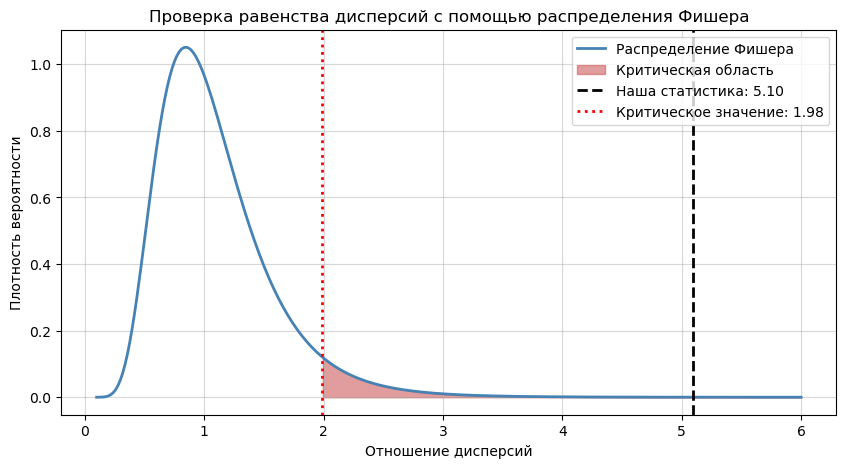

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import f

np.random.seed(42)

# Качество поставок от первого поставщика (стабильный, малый разброс)
качество_первый = np.random.normal(loc=100, scale=3, size=25)

# Качество поставок от второго поставщика (нестабильный, большой разброс)
качество_второй = np.random.normal(loc=100, scale=7, size=25)

# Расчет дисперсий (с поправкой на размер выборки)
дисперсия_первый = np.var(качество_первый, ddof=1)
дисперсия_второй = np.var(качество_второй, ddof=1)

# Размеры выборок и степени свободы
размер_1 = len(качество_первый)
размер_2 = len(качество_второй)
степени_свободы_1 = размер_1 - 1
степени_свободы_2 = размер_2 - 1

# Расчет статистики Фишера (большую дисперсию делим на меньшую)
if дисперсия_второй >= дисперсия_первый:
    статистика_фишера = дисперсия_второй / дисперсия_первый
    степени_числитель = степени_свободы_2
    степени_знаменатель = степени_свободы_1
else:
    статистика_фишера = дисперсия_первый / дисперсия_второй
    степени_числитель = степени_свободы_1
    степени_знаменатель = степени_свободы_2

# Критическое значение для уровня значимости 5 процентов (односторонний тест)
критическое_значение = f.ppf(q=0.95, dfn=степени_числитель, dfd=степени_знаменатель)

print(f"Дисперсия первого поставщика: {дисперсия_первый:.2f}")
print(f"Дисперсия второго поставщика: {дисперсия_второй:.2f}")
print(f"Статистика Фишера: {статистика_фишера:.2f}")
print(f"Критическое значение: {критическое_значение:.2f}")

if статистика_фишера > критическое_значение:
    print("Вывод: дисперсии значимо различаются. Второй поставщик менее стабилен.")
else:
    print("Вывод: значимой разницы в стабильности не обнаружено.")

# Визуализация распределения Фишера и положения нашей статистики
значения_оси = np.linspace(0.1, 6, 300)
плотность = f.pdf(x=значения_оси, dfn=степени_числитель, dfd=степени_знаменатель)

plt.figure(figsize=(10, 5))
plt.plot(значения_оси, плотность, color='steelblue', linewidth=2, 
         label='Распределение Фишера')
plt.fill_between(значения_оси, плотность, where=(значения_оси >= критическое_значение), 
                 color='indianred', alpha=0.6, label='Критическая область')
plt.axvline(x=статистика_фишера, color='black', linestyle='dashed', linewidth=2,
            label=f'Наша статистика: {статистика_фишера:.2f}')
plt.axvline(x=критическое_значение, color='red', linestyle='dotted', linewidth=2,
            label=f'Критическое значение: {критическое_значение:.2f}')

plt.title('Проверка равенства дисперсий с помощью распределения Фишера')
plt.xlabel('Отношение дисперсий')
plt.ylabel('Плотность вероятности')
plt.legend()
plt.grid(alpha=0.5)
plt.show()

## Практические выводы по распределению Фишера

1. Результат проверки: Рассчитанная статистика Фишера попадает в критическую область (правый красный хвост графика). Это означает, что с уровнем уверенности 95 процентов можно утверждать: второй поставщик действительно работает менее стабильно, чем первый.
2. Интерпретация графика: Кривая показывает, какие значения отношения дисперсий возможны, если на самом деле поставщики одинаково стабильны. Наша статистика оказалась в зоне маловероятных значений, поэтому гипотезу о равенстве дисперсий следует отвергнуть.
3. Решения для бизнеса:
   - Отдел закупок получил статистическое обоснование для пересмотра условий контракта со вторым поставщиком.
   - Возможные действия: потребовать от поставщика улучшений технологического процесса, ввести штрафные санкции за партии с отклонениями, либо переключиться на первого поставщика даже при более высокой цене.
   - Тест Фишера применим во всех задачах, где нужно сравнить стабильность двух процессов: производительность смен, качество продукции разных цехов, эффективность двух рекламных каналов.